# Deliverable 3 : Image captioning with InceptionV3 features and an attention GRU decoder, within the complete D1 → D2 → D3 workflow

**Author**:

| Name | Email |
|---|---|
| Zakarya Zitouni | zakarya.zitouni@viacesi.fr |

**Context.** TouNum digitises archives in bulk and wants to caption the photographs automatically. The images are of uneven quality, and many are not photographs (documents, schematics, drawings, paintings). This notebook trains, evaluates and saves the captioning network, then assembles the complete chain: the denoiser of Deliverable 2, the photo classifier of Deliverable 1, and the captioner.

**Data.** MS COCO 2017, official splits, no further splitting:
- **`train2017`** (118,287 images, about five captions each) trains the model.
- **`val2017`** (5,000 images) is used for model selection and evaluation.
- **`test2017`** (40,670 images, captions not public) is captioned and scored with the reference-free CLIPScore.

**Method.**
- **Pre-processing CNN.** A frozen, ImageNet-trained InceptionV3 maps each image to an 8 x 8 grid of 2,048-dimensional region features, computed once and stored on disk.
- **Captioning network.** A trainable CNN encoder on these features, and an RNN decoder made of two GRU layers with additive attention over the 64 regions (Up-Down form), which writes the caption word by word.
- **Training.** Cross-entropy with label smoothing, then self-critical sequence training (SCST) on the CIDEr-D reward.

**Coverage of the brief.**
- Complete schematic of the network, with the pre-processing CNN, the layers, their cells, types and roles: Section 6.
- InceptionV3 pre-processing into a compact representation stored on disk: Section 4.
- Text pre-processing (splitting on special characters, most frequent words, indexes, padding): Section 3.
- Code of the CNN and RNN: Section 6. Training: Sections 7 and 9.
- Loss curves on the training and validation sets: Section 8. Annotated test images: Section 10.
- The complete workflow from an unidentified image to a captioned photograph, with the models of Deliverables 1 and 2: Section 12.

**Notes on the brief.**
- **Relation to the Captioning Workshop.** The design is the workshop's: InceptionV3 features, a Dense encoder, and a GRU decoder with additive (Bahdanau) attention. The decoder is a stronger version of it:
  - two GRU layers (attention and language, Up-Down form) instead of one;
  - a second training stage, SCST, which raises the validation CIDEr-D from 0.948 to 1.054 (Section 9).
- **The CNN encoder has no convolutions.** As in the workshop's `CNN_Encoder`, the trainable encoder is a LayerNorm and a Dense layer (2,048 to 512, ReLU) applied to each of the 64 regions. The convolutions are those of InceptionV3, which is frozen and runs once per image (Section 4). In this notebook, "CNN encoder" denotes the frozen InceptionV3 together with this trainable Dense part.

**Beyond the brief**, each in its own section with its justification:
- **E1**, whether the denoiser improves the captions of noisy photographs;
- **E2**, the order of the chain and the errors of the photo gate under noise;
- **E3**, gender errors in the captions, which matter for publication;
- **E4**, a second captioner (ConvNeXt-XL features and a Transformer decoder), which measures what a stronger CNN and decoder would add.

## Section 1 - Configuration

- **Paths.** COCO, the stored features of the two CNNs, the training runs, and the saved models of the three deliverables.
- **Hyper-parameters.** `GRU_CFG` is the main captioner; `TFM_CFG` the second captioner of Extension E4. Values were chosen on 20,000-image pilots (Extension E4).
- **`RETRAIN = False`.** The features, weights and evaluation results stored under `FEAT_DIR` are reused; any missing one is recomputed by the code of its section.

In [1]:
import os, re, json, math, time, textwrap, collections, warnings
from pathlib import Path
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import tensorflow as tf
import keras
from keras import layers
from PIL import Image
from IPython.display import display

warnings.filterwarnings("ignore")
tf.get_logger().setLevel("ERROR")
pd.set_option("display.width", 220)
# GPU memory is capped so that allocations never spill into host memory
for gpu in tf.config.list_physical_devices("GPU"):
    tf.config.set_logical_device_configuration(gpu, [tf.config.LogicalDeviceConfiguration(memory_limit=5500)])

# ---------------- SETTINGS ----------------
COCO_ROOT   = Path("/home/zakar/tf-cache/coco_local")         # train2017/, val2017/, test2017/, annotations/
INC_DIR     = Path("/home/zakar/tf-cache/captioning")         # InceptionV3 features of train2017 and val2017 (float16)
FEAT_DIR    = Path("/home/zakar/tf-cache/captioning_v2")      # ConvNeXt-XL features of the three splits (float16), runs/
RUNS        = FEAT_DIR / "runs"                                # weights, histories and evaluation results of every run
PROJECT_DIR = Path.cwd().parent                                 # the repository root (this notebook runs from 3 - Captioner/)
D1_MODEL    = PROJECT_DIR / "1 - Binary Classifier" / "modele_photo.keras"     # Deliverable 1: photo / not photo
D2_MODEL    = PROJECT_DIR / "2 - Denoiser" / "cache" / "denoiser_coco.keras"  # Deliverable 2: first-stage denoiser (DenoiserNotebook, Section 9)
D1_DATA     = Path("/mnt/c/Users/zakar/OneDrive/Desktop/Documents/DataSet")  # Deliverable 1 images (5 classes), as in ClassifierNotebook
RETRAIN     = False

T         = 22           # caption length limit, <start> and <end> included (at most 20 words)
MIN_COUNT = 5            # words seen fewer times in the training captions become <unk>
GRU_CFG = dict(emb=512, enc=512, units=768, dropout=0.5, enc_drop=0.2,                         # network (Section 6)
               lr=1e-3, wd=0.01, beta2=0.999, smooth=0.1, clip=5.0, batch=128, img_batch=0,    # cross-entropy (Section 7)
               epochs=15, patience=4,
               scst_lr=5e-5, scst_batch=50, scst_k=5, scst_epochs=10, scst_patience=3)         # SCST (Section 9)
TFM_CFG = dict(d=512, enc_layers=3, dec_layers=3, heads=8, ff=2048, dropout=0.1,               # Transformer (Extension E4)
               lr=6e-4, wd=0.01, beta2=0.98, smooth=0.1, clip=1.0, img_batch=25, per_img=5, epochs=12, patience=3,
               scst_lr=5e-5, scst_batch=50, scst_k=5, scst_epochs=10, scst_patience=3)
MODELS = {"gru": dict(label="InceptionV3 + Up-Down GRU", cnn="inception", cfg=GRU_CFG, run=RUNS / "gru_inception",
                      save=PROJECT_DIR / "3 - Captioner" / "leyenda_captioner_gru"),
          "transformer": dict(label="ConvNeXt-XL + Transformer", cnn="convnext", cfg=TFM_CFG, run=RUNS / "final",
                              save=PROJECT_DIR / "3 - Captioner" / "leyenda_captioner")}
SEED = 42
# ------------------------------------------

PAD, UNK, START, END = 0, 1, 2, 3
keras.utils.set_random_seed(SEED)
for m in MODELS.values():
    m["run"].mkdir(parents=True, exist_ok=True)
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)
for p in [COCO_ROOT / s for s in ("train2017", "val2017", "test2017")] + [D1_MODEL, D2_MODEL, D1_DATA]:
    print(f"{str(p):80s} exists: {p.exists()}")

I0000 00:00:1793877735.080157  574772 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1793877736.276415  574772 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0 | Keras 3.15.1
/home/zakar/tf-cache/coco_local/train2017                                        exists: True
/home/zakar/tf-cache/coco_local/val2017                                          exists: True
/home/zakar/tf-cache/coco_local/test2017                                         exists: True
/mnt/c/Users/zakar/OneDrive/Desktop/CESI Learning/deliverable1/modele_photo.keras exists: True
/mnt/c/Users/zakar/OneDrive/Desktop/CESI Learning/deliverable2/denoiser_coco.keras exists: True
/mnt/c/Users/zakar/OneDrive/Desktop/Documents/DataSet                            exists: True


## Section 2 - Data

- **Splits.** The three official COCO 2017 splits are used as they are. No image contributes to more than one split, and the vocabulary (Section 3) is fitted on training captions only.
- **Order.** Each split is put in a fixed random order (seed 42). It is the order in which the features are stored, so that contiguous reads during training mix images of different kinds.

train2017 images 118,287 | captions 591,753
val2017   images   5,000 | captions  25,014
test2017  images  40,670 | captions       0


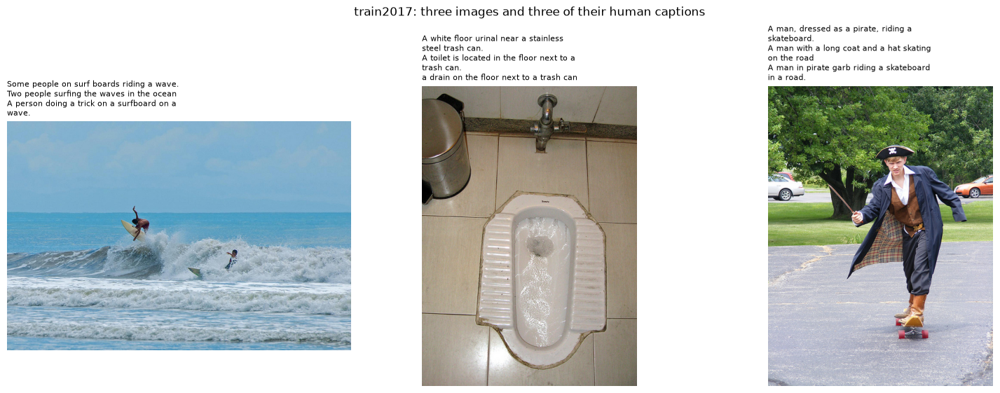

In [2]:
def split_words(t):
    return re.findall(r"[a-z0-9']+", t.lower())


def image_names(split):
    names = sorted(p.name for p in (COCO_ROOT / split).iterdir())
    return [names[i] for i in np.random.default_rng(SEED).permutation(len(names))]


class Split:
    """One COCO split: image names in the stored order, tokenised captions, and the features of each CNN (Section 4)."""
    def __init__(self, split):
        self.split, self.names = split, image_names(split)
        self.caps, self.raw = [[] for _ in self.names], [[] for _ in self.names]
        self.stores, self.cur = {}, None
        if split != "test2017":
            index = {int(n[:-4]): i for i, n in enumerate(self.names)}
            for a in json.loads((COCO_ROOT / "annotations" / f"captions_{split}.json").read_text())["annotations"]:
                if a["image_id"] in index:
                    self.caps[index[a["image_id"]]].append(split_words(a["caption"]))
                    self.raw[index[a["image_id"]]].append(a["caption"].strip())

    def path(self, i):
        return str(COCO_ROOT / self.split / self.names[i])

    def attach(self, cnn, store):
        # store: a float16 memmap (images, regions, channels), or a function computing the features from image paths
        self.stores[cnn] = store

    def use(self, cnn):
        self.cur = cnn

    def features(self, a, b):
        s = self.stores[self.cur]
        return s([self.path(i) for i in range(a, b)]) if callable(s) else np.asarray(s[a:b], dtype=np.float32)


train, val, test = Split("train2017"), Split("val2017"), Split("test2017")
for s in (train, val, test):
    print(f"{s.split:9s} images {len(s.names):7,d} | captions {sum(len(c) for c in s.caps):7,d}")

fig, axes = plt.subplots(1, 3, figsize=(15, 5.5), constrained_layout=True)
for ax, i in zip(axes, range(3)):
    ax.imshow(Image.open(train.path(i)).convert("RGB")); ax.axis("off")
    ax.set_title("\n".join(textwrap.fill(c, 42) for c in train.raw[i][:3]), fontsize=8, loc="left")
plt.suptitle("train2017: three images and three of their human captions", fontsize=12)
plt.show()

## Section 3 - Text pre-processing

- **Splitting.** Each caption is lower-cased and split on every character outside `[a-z0-9']`, so punctuation and other special characters are dropped.
- **Most frequent words.** The vocabulary keeps the words that appear at least `MIN_COUNT = 5` times in the training captions, sorted by frequency, plus `<pad>`, `<unk>`, `<start>` and `<end>`. Rarer words map to `<unk>`, which the decoder is never allowed to emit (Section 10).
- **Indexes.** Each word is replaced by its index in the vocabulary; the embedding layer of the decoder (Section 6) turns each index into a 512-dimensional vector.
- **Padding.** Training uses the captions of at most 20 words, framed as `<start> w_1 ... w_n <end>` and padded with `<pad>` (index 0) to the common length `T = 22`. Padded positions are masked out of the loss. Evaluation compares against all references, whatever their length.

In [3]:
def build_vocab(caps, min_count=MIN_COUNT):
    c = collections.Counter(w for cs in caps for x in cs for w in x)
    words = ["<pad>", "<unk>", "<start>", "<end>"] + [w for w, n in c.most_common() if n >= min_count]
    return words, {w: i for i, w in enumerate(words)}


def encode_all(caps, w2i, T=T):
    """(image index, padded word ids) for every caption that fits in T tokens."""
    im, seq = [], []
    for i, cs in enumerate(caps):
        for x in cs:
            if len(x) + 2 <= T:
                ids = [START] + [w2i.get(w, UNK) for w in x] + [END]
                seq.append(ids + [PAD] * (T - len(ids))); im.append(i)
    return np.array(im, np.int32), np.array(seq, np.int32)


words, w2i = build_vocab(train.caps); V = len(words)
im, seq = encode_all(train.caps, w2i); vim, vseq = encode_all(val.caps, w2i)
n_caps = sum(len(c) for c in train.caps)
lengths = np.array([len(x) for cs in train.caps for x in cs])
print(f"vocabulary: {V:,d} entries | training captions kept: {len(im):,d} of {n_caps:,d} ({1 - len(im) / n_caps:.2%} longer than 20 words)")
print(f"caption length: median {np.median(lengths):.0f} words, 99th percentile {np.percentile(lengths, 99):.0f}"
      f" | <unk> share of the kept words: {(seq == UNK).sum() / ((seq > END).sum()):.3%}")
print("first entries:", words[:16])
print("example:", train.raw[0][0], "->", seq[0].tolist())
for m in MODELS.values():
    if (m["run"] / "vocab.json").exists():
        assert json.loads((m["run"] / "vocab.json").read_text()) == words, "stored weights belong to another vocabulary"

vocabulary: 10,297 entries | training captions kept: 588,185 of 591,753 (0.60% longer than 20 words)
caption length: median 10 words, 99th percentile 19 | <unk> share of the kept words: 0.443%
first entries: ['<pad>', '<unk>', '<start>', '<end>', 'a', 'on', 'of', 'the', 'in', 'with', 'and', 'is', 'man', 'to', 'sitting', 'an']
example: Some people on surf boards riding a wave. -> [2, 31, 19, 5, 304, 580, 47, 4, 195, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


## Section 4 - Image pre-processing with InceptionV3

**CNN.** InceptionV3 (Szegedy et al., 2016), trained on ImageNet classification, is the pre-processing CNN required by the brief:
- Each image is decoded to RGB, resized bilinearly to 299 x 299 without keeping the aspect ratio, and scaled to [-1, 1] (`inception_v3.preprocess_input`).
- The classification head (global pooling and the 1,000-class layer) is removed (`include_top=False`), and the weights are frozen.
- The output of the last Inception module (`mixed10`) is an 8 x 8 x 2,048 map, reshaped to 64 regions x 2,048 features. Each region describes a 37 x 37-pixel cell of the input together with its receptive field; keeping the grid lets the decoder attend to regions.

**Compact representation on disk.** Because the CNN is frozen, each image is encoded once and stored as float16 in one memmap per split: 262 KB per image instead of decoding and running the CNN at every epoch. `test2017` features are not stored; they are computed from the image files when the test images are captioned, with the same function.

**Check.** Features recomputed from the image files must agree with the stored ones.

In [4]:
CNNS = {"inception": (lambda: keras.applications.InceptionV3(include_top=False, weights="imagenet"), 299,
                      keras.applications.inception_v3.preprocess_input),
        "convnext": (lambda: keras.applications.ConvNeXtXLarge(include_top=False, weights="imagenet"), 384, lambda x: x)}


def feature_files(cnn, split):
    if cnn == "inception":
        return INC_DIR / f"{split}.f16", INC_DIR / f"{split}.json"
    return FEAT_DIR / f"full_{split}.f16", FEAT_DIR / f"full_{split}.json"


def stored_names(meta):
    m = json.loads(meta.read_text())
    return m if isinstance(m, list) else m["names"]


def load_image(path, size):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    return tf.image.resize(tf.cast(img, tf.float32), (size, size))


_cnn = {}


def extractor(cnn):
    """Function: image paths -> (n, regions, channels) float32 features, rounded to float16 like the stored ones."""
    if cnn not in _cnn:
        make, size, prep = CNNS[cnn]; base = make()
        grid = base.compute_output_shape((1, size, size, 3)); R_, D_ = grid[1] * grid[2], grid[3]
        net = tf.function(lambda x: tf.cast(tf.reshape(base(prep(x), training=False), (-1, R_, D_)), tf.float16))

        def extract(paths, batch=8):
            out = [net(tf.stack([load_image(p, size) for p in paths[s:s + batch]])).numpy() for s in range(0, len(paths), batch)]
            return np.concatenate(out).astype(np.float32)
        _cnn[cnn] = dict(base=base, net=net, extract=extract, R=R_, D=D_, size=size)
    return _cnn[cnn]


def extract_split(s, cnn, batch=8):
    data, meta = feature_files(cnn, s.split); x = extractor(cnn)
    mm = np.memmap(data, dtype=np.float16, mode="w+", shape=(len(s.names), x["R"], x["D"]))
    for a in range(0, len(s.names), 512):
        mm[a:a + 512] = x["extract"]([s.path(i) for i in range(a, min(a + 512, len(s.names)))], batch)
    mm.flush(); del mm
    meta.write_text(json.dumps(s.names if cnn == "inception" else {"names": s.names, "R": x["R"], "D": x["D"]}))


GRID = {"inception": (64, 2048), "convnext": (144, 2048)}
rows = []
for cnn, (R_, D_) in GRID.items():
    for s in (val, train, test):
        data, meta = feature_files(cnn, s.split)
        if cnn == "inception" and s.split == "test2017":
            s.attach(cnn, lambda paths: extractor("inception")["extract"](paths)); continue
        if RETRAIN or not (meta.exists() and data.stat().st_size == len(s.names) * R_ * D_ * 2):
            extract_split(s, cnn)
        assert stored_names(meta) == s.names, "stored features are in another image order"
        s.attach(cnn, np.memmap(data, dtype=np.float16, mode="r", shape=(len(s.names), R_, D_)))
        rows.append({"CNN": cnn, "split": s.split, "stored shape": str((len(s.names), R_, D_)), "GB": round(data.stat().st_size / 1e9, 1)})
display(pd.DataFrame(rows).style.hide(axis="index"))

inc = extractor("inception")
convs = [l for l in inc["base"].layers if isinstance(l, layers.Conv2D)]
modules = [l.name for l in inc["base"].layers if re.fullmatch(r"mixed\d+", l.name)]
print(f"InceptionV3 without its head: {len(inc['base'].layers)} layers, of which {len(convs)} convolutions, "
      f"{inc['base'].count_params():,d} frozen weights | {len(modules)} Inception modules: {', '.join(modules)}")
print(f"output: {inc['base'].output.shape[1:]} -> {inc['R']} regions x {inc['D']} features")
for s in (train, val, test):
    s.use("inception")
fresh = inc["extract"]([val.path(i) for i in range(16)]); disk = val.features(0, 16)
cos = (fresh * disk).sum(-1) / (np.linalg.norm(fresh, axis=-1) * np.linalg.norm(disk, axis=-1) + 1e-9)
print(f"features from the image files vs stored (16 val images): lowest cosine of a region vector {cos.min():.4f}")
R, D = inc["R"], inc["D"]

CNN,split,stored shape,GB
inception,val2017,"(5000, 64, 2048)",1.300000
inception,train2017,"(118287, 64, 2048)",31.000000
convnext,val2017,"(5000, 144, 2048)",2.900000
convnext,train2017,"(118287, 144, 2048)",69.800000
convnext,test2017,"(40670, 144, 2048)",24.000000


InceptionV3 without its head: 311 layers, of which 94 convolutions, 21,802,784 frozen weights | 11 Inception modules: mixed0, mixed1, mixed2, mixed3, mixed4, mixed5, mixed6, mixed7, mixed8, mixed9, mixed10
output: (None, None, 2048) -> 64 regions x 2048 features


features from the image files vs stored (16 val images): lowest cosine of a region vector 1.0000


## Section 5 - Input pipeline

**GRU batches.** Each batch holds 128 (image, caption) pairs. The features are read in contiguous chunks of 512 images; the chunks are visited in random order and the pairs are shuffled within each chunk, so that reads stay sequential on disk while the batches are randomised (`pair_batches`).

**Transformer batches** (Extension E4). Each batch holds 25 images with 5 of their captions, so that the encoder runs once per image (`image_caption_batches`).

In [5]:
def chunks(n_images, rng, chunk=512):
    offset = int(rng.integers(chunk))
    bounds = [0] + list(range(offset, n_images, chunk)) + [n_images]
    pieces = [(a, b) for a, b in zip(bounds[:-1], bounds[1:]) if b > a]
    return [pieces[k] for k in rng.permutation(len(pieces))]


def pair_batches(store, im, seq, n_images, batch, rng):
    """(features, caption) pairs, shuffled inside each chunk."""
    start = np.searchsorted(im, np.arange(n_images + 1))
    for a, b in chunks(n_images, rng):
        f = store.features(a, b); pairs = rng.permutation(np.arange(start[a], start[b]))
        for s in range(0, len(pairs) - batch + 1, batch):
            p = pairs[s:s + batch]
            yield f[im[p] - a], seq[p]


def image_batches(store, n_images, batch, rng):
    """Image indices and features, each image once per epoch."""
    for a, b in chunks(n_images, rng):
        f = store.features(a, b); order = rng.permutation(b - a)
        for s in range(0, len(order) - batch + 1, batch):
            o = order[s:s + batch]
            yield a + o, f[o]


def image_caption_batches(store, im, seq, n_images, nb, rng, per):
    """nb images, each with `per` of its captions; an image without any caption of at most 20 words is replaced by
    the first image of the batch."""
    start = np.searchsorted(im, np.arange(n_images + 1))
    for idx, f in image_batches(store, n_images, nb, rng):
        rows = []
        for j, i in enumerate(idx):
            a, b = start[i], start[i + 1]
            if b == a:
                f[j] = f[0]; a, b = start[idx[0]], start[idx[0] + 1]
            rows.append(rng.choice(np.arange(a, b), per, replace=b - a < per))
        yield f, seq[np.concatenate(rows)]


f, y = next(pair_batches(train, im, seq, len(train.names), GRU_CFG["batch"], np.random.default_rng(0)))
print("one batch: features", f.shape, f.dtype, "| captions", y.shape, y.dtype)
print("first caption:", " ".join(words[i] for i in y[0] if i != PAD))

one batch: features (128, 64, 2048) float32 | captions (128, 22) int32
first caption: <start> a chopping board with cut up carrots broccoli and scallions <end>


## Section 6 - Architecture of the captioning network

**Encoder-decoder.** The network follows the encoder-decoder model of the Captioning Workshop: a CNN encoder gives the RNN decoder a representation of the image, from which the decoder predicts the caption one word at a time. The decoder is the Up-Down model of Anderson et al. (2018), with GRU cells. Notation: $f_i$ for the 64 InceptionV3 region features, $a_i \in \mathbb{R}^{512}$ for the encoded regions, $\bar a$ for their mean, $y_{t-1}$ for the previous word.

**CNN part.**
* **Pre-processing CNN** (InceptionV3, frozen, Section 4): image → 64 regions x 2,048 features, computed once.
* **Encoder** (`Encoder`, trainable, 1 layer): $a_i = \mathrm{ReLU}(W_e\,\mathrm{LN}(f_i) + b_e)$, applied to each region, 2,048 → 512. The LayerNorm puts the frozen features on a common scale; dropout 0.2 is applied to $a_i$ during training.

**RNN part** (`UpDownDecoder`), at each step $t$:
* **Embedding** (10,297 x 512): the previous word $y_{t-1}$ as a vector $E y_{t-1}$.
* **Attention GRU** (1st recurrent layer, 768 cells): $h^1_t = \mathrm{GRU}_1(h^1_{t-1}, [h^2_{t-1}; \bar a; E y_{t-1}])$. It forms the attention query from the language state, the global image and the previous word.
* **Additive attention** (Bahdanau et al., 2015; 768 units): $\alpha_t = \mathrm{softmax}_i(v^\top \tanh(W_1 a_i + W_2 h^1_t))$ over the 64 regions, and the context $z_t = \sum_i \alpha_{ti} a_i$.
* **Language GRU** (2nd recurrent layer, 768 cells): $h^2_t = \mathrm{GRU}_2(h^2_{t-1}, [z_t; h^1_t])$. It writes the word.
* **Output layer.** Dropout 0.5, a projection to the 512-dimensional embedding space, and logits $E\,(W_o h^2_t)$ over the vocabulary, with the output matrix tied to the embedding (Press and Wolf, 2017), which saves 5.3 M weights. A softmax gives the distribution of the next word.

**Changes from the workshop model.**
* The workshop's single GRU had to carry both the attention query and the language state. The second GRU separates the two roles.
* The workshop decoder called its GRU without the previous state, so the recurrence restarted at every word. Here both states are passed from step to step.
* The workshop's encoder had no normalisation; the LayerNorm keeps the 2,048 InceptionV3 channels on a common scale.

In [6]:
class Encoder(keras.Model):
    """CNN side of the captioner: LayerNorm on the frozen features, then Dense + ReLU per region."""
    def __init__(self, dim, dropout=0.0):
        super().__init__()
        self.norm = layers.LayerNormalization(); self.fc = layers.Dense(dim); self.drop = layers.Dropout(dropout)

    def call(self, x, training=False):
        return self.drop(tf.nn.relu(self.fc(self.norm(x))), training=training)


class Attention(keras.Model):
    """Additive attention: one weight per region, from the regions and the query state."""
    def __init__(self, units):
        super().__init__(); self.W1 = layers.Dense(units); self.W2 = layers.Dense(units); self.V = layers.Dense(1)

    def call(self, features, keys, hidden):
        a = tf.nn.softmax(self.V(tf.nn.tanh(keys + self.W2(hidden)[:, None])), axis=1)
        return tf.reduce_sum(a * features, axis=1), a


class UpDownDecoder(keras.Model):
    """Two GRUs (Anderson et al., 2018): an attention GRU that forms the query, a language GRU that writes."""
    def __init__(self, emb, units, vocab, dropout=0.5):
        super().__init__(); self.units = units
        self.embedding = layers.Embedding(vocab, emb)
        self.c1 = layers.GRUCell(units); self.c2 = layers.GRUCell(units)
        self.attention = Attention(units); self.drop = layers.Dropout(dropout)
        self.fc = layers.Dense(emb)                          # to the embedding space: output weights tied to the embedding

    def initial_state(self, n):
        z = tf.zeros((n, self.units)); return (z, z)

    def prepare(self, features):
        # attention keys W1 a_i and mean region, computed once per image
        return self.attention.W1(features), tf.reduce_mean(features, axis=1)

    def step(self, word, features, prepared, state, training=False):
        keys, pooled = prepared; h1, h2 = state
        h1, _ = self.c1(tf.concat([h2, pooled, self.embedding(word)], -1), h1)
        ctx, a = self.attention(features, keys, h1)
        h2, _ = self.c2(tf.concat([ctx, self.drop(h1, training=training)], -1), h2)
        return h2, (h1, h2), a

    def logits(self, out, training=False):
        return tf.matmul(self.fc(self.drop(out, training=training)), self.embedding.embeddings, transpose_b=True)


def n_params(*models):
    return sum(int(np.prod(v.shape)) for m in models for v in m.trainable_variables)


def build_gru(cfg, V, R):
    enc = Encoder(cfg["enc"], cfg["enc_drop"]); dec = UpDownDecoder(cfg["emb"], cfg["units"], V, cfg["dropout"])
    f0 = enc(tf.zeros((1, R, D))); o0, *_ = dec.step(tf.zeros((1,), tf.int32), f0, dec.prepare(f0), dec.initial_state(1))
    dec.logits(o0)                                # all weights exist before any are loaded
    dec.built = True                              # the decoder is used through step/logits, never through call()
    return enc, dec


enc, dec = build_gru(GRU_CFG, V, R)
parts = [("Encoder", "LayerNorm", "2048", "(64, 2048)", enc.norm, "scales the frozen InceptionV3 features"),
         ("Encoder", "Dense + ReLU", "512", "(64, 512)", enc.fc, "encodes each region a_i"),
         ("Decoder", "Embedding", f"{V:,d} x 512", "(512,)", dec.embedding, "previous word -> vector; also the output matrix"),
         ("Decoder", "GRU 1 (attention)", "768 cells", "(768,)", dec.c1, "query h1 from h2, mean region and word"),
         ("Decoder", "additive attention", "768 units", "(64,) weights, (512,) context", dec.attention, "weights the 64 regions"),
         ("Decoder", "GRU 2 (language)", "768 cells", "(768,)", dec.c2, "language state h2 from context and h1"),
         ("Decoder", "Dropout + Dense", "512", "(512,)", dec.fc, "projection to the embedding space"),
         ("Decoder", "tied logits + softmax", f"{V:,d}", f"({V:,d},)", None, "distribution of the next word")]
display(pd.DataFrame([{"part": p, "layer": l, "size": s, "output per image / step": o,
                       "trainable weights": f"{n_params(m):,d}" if m is not None else "0 (tied)", "role": r}
                      for p, l, s, o, m, r in parts]).style.hide(axis="index"))
print(f"trainable weights: encoder {n_params(enc):,d} + decoder {n_params(dec):,d} = {n_params(enc, dec):,d} "
      f"| frozen InceptionV3: {inc['base'].count_params():,d}")

part,layer,size,output per image / step,trainable weights,role
Encoder,LayerNorm,2048,"(64, 2048)","4,096",scales the frozen InceptionV3 features
Encoder,Dense + ReLU,512,"(64, 512)","1,049,088",encodes each region a_i
Decoder,Embedding,"10,297 x 512","(512,)","5,272,064",previous word -> vector; also the output matrix
Decoder,GRU 1 (attention),768 cells,"(768,)","5,902,848","query h1 from h2, mean region and word"
Decoder,additive attention,768 units,"(64,) weights, (512,) context","985,345",weights the 64 regions
Decoder,GRU 2 (language),768 cells,"(768,)","4,723,200",language state h2 from context and h1
Decoder,Dropout + Dense,512,"(512,)","393,728",projection to the embedding space
Decoder,tied logits + softmax,"10,297","(10,297,)",0 (tied),distribution of the next word


trainable weights: encoder 1,053,184 + decoder 17,277,185 = 18,330,369 | frozen InceptionV3: 21,802,784


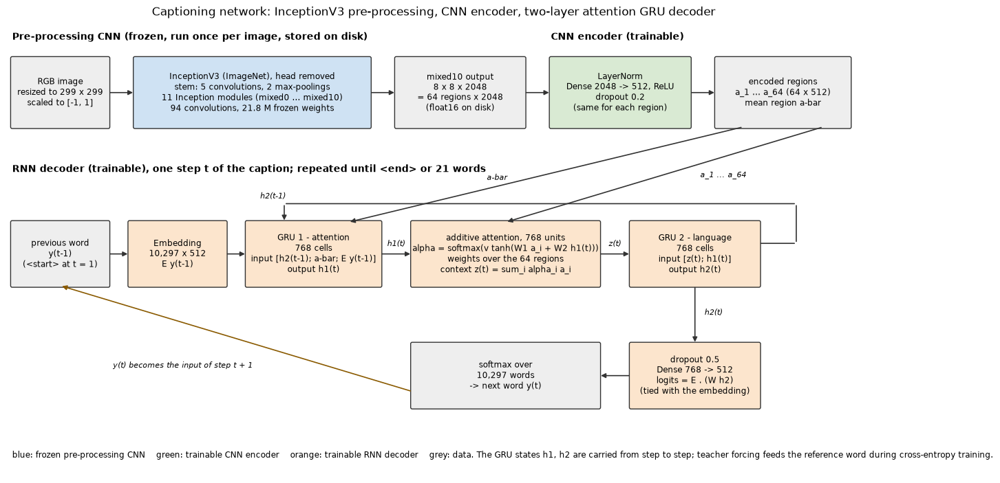

In [7]:
# complete schematic of the captioning network
fig, ax = plt.subplots(figsize=(16, 8.6)); ax.set_xlim(0, 16); ax.set_ylim(0, 8.6); ax.axis("off")
def box(x, y, w, h, text, color, fs=8.8):
    ax.add_patch(mpatches.FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.03", fc=color, ec="#333333", lw=1))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=fs)
def arrow(p, q, text=None, dx=0.0, dy=0.12, style="-|>", color="#333333"):
    ax.annotate("", q, p, arrowprops=dict(arrowstyle=style, lw=1.2, color=color))
    if text:
        ax.text((p[0] + q[0]) / 2 + dx, (p[1] + q[1]) / 2 + dy, text, fontsize=8, ha="center", style="italic")
ax.text(0.1, 8.25, "Pre-processing CNN (frozen, run once per image, stored on disk)", fontsize=10, weight="bold")
box(0.1, 6.6, 1.8, 1.3, "RGB image\nresized to 299 x 299\nscaled to [-1, 1]", "#eeeeee")
box(2.4, 6.6, 4.4, 1.3, f"InceptionV3 (ImageNet), head removed\nstem: 5 convolutions, 2 max-poolings\n"
                        f"11 Inception modules (mixed0 ... mixed10)\n{len(convs)} convolutions, {inc['base'].count_params() / 1e6:.1f} M frozen weights", "#cfe2f3")
box(7.3, 6.6, 2.4, 1.3, "mixed10 output\n8 x 8 x 2048\n= 64 regions x 2048\n(float16 on disk)", "#eeeeee")
arrow((1.9, 7.25), (2.4, 7.25)); arrow((6.8, 7.25), (7.3, 7.25))
ax.text(10.2, 8.25, "CNN encoder (trainable)", fontsize=10, weight="bold")
box(10.2, 6.6, 2.6, 1.3, "LayerNorm\nDense 2048 -> 512, ReLU\ndropout 0.2\n(same for each region)", "#d9ead3")
box(13.3, 6.6, 2.5, 1.3, "encoded regions\na_1 ... a_64 (64 x 512)\nmean region a-bar", "#eeeeee")
arrow((9.7, 7.25), (10.2, 7.25)); arrow((12.8, 7.25), (13.3, 7.25))
ax.text(0.1, 5.75, "RNN decoder (trainable), one step t of the caption; repeated until <end> or 21 words", fontsize=10, weight="bold")
box(0.1, 3.6, 1.8, 1.2, "previous word\ny(t-1)\n(<start> at t = 1)", "#eeeeee")
box(2.3, 3.6, 1.8, 1.2, "Embedding\n10,297 x 512\nE y(t-1)", "#fce5cd")
box(4.5, 3.6, 2.5, 1.2, "GRU 1 - attention\n768 cells\ninput [h2(t-1); a-bar; E y(t-1)]\noutput h1(t)", "#fce5cd")
box(7.6, 3.6, 3.5, 1.2, "additive attention, 768 units\nalpha = softmax(v tanh(W1 a_i + W2 h1(t)))\nweights over the 64 regions\ncontext z(t) = sum_i alpha_i a_i", "#fce5cd")
box(11.7, 3.6, 2.4, 1.2, "GRU 2 - language\n768 cells\ninput [z(t); h1(t)]\noutput h2(t)", "#fce5cd")
box(11.7, 1.3, 2.4, 1.2, "dropout 0.5\nDense 768 -> 512\nlogits = E . (W h2)\n(tied with the embedding)", "#fce5cd")
box(7.6, 1.3, 3.5, 1.2, "softmax over\n10,297 words\n-> next word y(t)", "#eeeeee")
arrow((1.9, 4.2), (2.3, 4.2)); arrow((4.1, 4.2), (4.5, 4.2)); arrow((7.0, 4.2), (7.6, 4.2), "h1(t)", dy=0.15)
arrow((11.1, 4.2), (11.7, 4.2), "z(t)", dy=0.15); arrow((12.9, 3.6), (12.9, 2.5), "h2(t)", dx=0.35, dy=0)
arrow((11.7, 1.9), (11.1, 1.9))
arrow((15.3, 6.6), (9.35, 4.8)); ax.text(13.0, 5.65, "a_1 ... a_64", fontsize=8, style="italic")
arrow((13.8, 6.6), (6.4, 4.8)); ax.text(9.0, 5.6, "a-bar", fontsize=8, style="italic")
arrow((7.6, 1.6), (1.0, 3.6), "y(t) becomes the input of step t + 1", dx=-1.0, dy=-0.55, color="#8a5a00")
arrow((14.1, 4.4), (14.8, 4.4), style="-"); arrow((14.8, 4.4), (14.8, 5.15), style="-"); arrow((14.8, 5.15), (5.2, 5.15), style="-")
arrow((5.2, 5.15), (5.2, 4.8)); ax.text(4.75, 5.25, "h2(t-1)", fontsize=8, style="italic")
ax.text(0.1, 0.35, "blue: frozen pre-processing CNN    green: trainable CNN encoder    orange: trainable RNN decoder    grey: data. "
        "The GRU states h1, h2 are carried from step to step; teacher forcing feeds the reference word during cross-entropy training.", fontsize=8.5)
ax.set_title("Captioning network: InceptionV3 pre-processing, CNN encoder, two-layer attention GRU decoder", fontsize=12)
plt.show()

## Section 7 - Cross-entropy training

**Objective.** With teacher forcing, the decoder receives the reference prefix and the loss is the cross-entropy of each next word over the non-padding positions, with label smoothing 0.1: $\mathcal L = (1-\epsilon)\,\mathrm{CE} - \epsilon\,\overline{\log p}$.

**Optimisation.**
* AdamW with weight decay 0.01, batches of 128 (image, caption) pairs.
* The learning rate rises linearly to $10^{-3}$ over the first epoch, then follows a cosine decay to zero at epoch 15.
* Gradients are clipped to global norm 5.

**Monitoring.** After each epoch, the validation cross-entropy (without smoothing) is computed, together with BLEU-4 and CIDEr-D of greedy captions on all 5,000 `val2017` images.

**Checkpoint.** The weights with the best validation CIDEr-D are kept. Training stops if CIDEr-D does not improve for 4 epochs.

**Metrics.** The implementations below are used for monitoring. Section 10 reports the official `pycocoevalcap` scores.
* **BLEU** (Papineni et al., 2002): corpus-level, with clipped n-gram precision and a brevity penalty.
* **CIDEr-D** (Vedantam et al., 2015): the mean cosine similarity of TF-IDF n-gram vectors ($n \le 4$), with clipped counts and a Gaussian length penalty ($\sigma = 6$).

**Shared code.** The training and decoding functions below serve both captioners; `use()` selects the model, its features and its run folder.

In [8]:
def bleu(references, hypotheses, max_n=4):
    clipped, total = [0] * max_n, [0] * max_n; hl = rl = 0
    for refs, hyp in zip(references, hypotheses):
        hl += len(hyp); rl += min((abs(len(r) - len(hyp)), len(r)) for r in refs)[1]
        for n in range(1, max_n + 1):
            hc = collections.Counter(tuple(hyp[i:i + n]) for i in range(len(hyp) - n + 1))
            mr = collections.Counter()
            for r in refs:
                for g, c in collections.Counter(tuple(r[i:i + n]) for i in range(len(r) - n + 1)).items():
                    mr[g] = max(mr[g], c)
            clipped[n - 1] += sum(min(c, mr[g]) for g, c in hc.items()); total[n - 1] += sum(hc.values())
    bp = 1.0 if hl >= rl else math.exp(1 - rl / max(hl, 1))
    out, s = [], 0.0
    for n in range(max_n):
        s += math.log(max(clipped[n], 1e-9) / max(total[n], 1)); out.append(bp * math.exp(s / (n + 1)))
    return out


def grams(words_):
    return collections.Counter(tuple(words_[i:i + n]) for n in range(1, 5) for i in range(len(words_) - n + 1))


class Cider:
    """CIDEr-D. Document frequencies from a reference corpus, given once."""
    def __init__(self, corpus_refs, sigma=6.0, min_df=1):
        df = collections.Counter()
        for refs in corpus_refs:
            df.update({g for r in refs for g in grams(r)})
        self.df = {g: c for g, c in df.items() if c >= min_df} if min_df > 1 else dict(df)
        self.log_n = math.log(max(len(corpus_refs), 2)); self.sigma = sigma

    def vec(self, words_):
        counts = grams(words_); vec, norm = [{} for _ in range(4)], [0.0] * 4
        for g, c in counts.items():
            n = len(g) - 1; w = c * (self.log_n - math.log(max(self.df.get(g, 1), 1)))
            vec[n][g] = w; norm[n] += w * w
        return vec, [math.sqrt(x) for x in norm], len(words_)

    def score_vecs(self, h, ref_vecs):
        hv, hn, hl = h; total = 0.0
        for rv, rn, rl in ref_vecs:
            sim = 0.0
            for n in range(4):
                if hn[n] > 0 and rn[n] > 0:
                    sim += sum(min(v, rv[n].get(g, 0.0)) * rv[n].get(g, 0.0) for g, v in hv[n].items()) / (hn[n] * rn[n])
            total += sim * math.exp(-((hl - rl) ** 2) / (2 * self.sigma ** 2))
        return 10.0 * total / (4 * len(ref_vecs))

    def scores(self, references, hypotheses):
        return np.array([self.score_vecs(self.vec(h), [self.vec(r) for r in refs]) for refs, h in zip(references, hypotheses)])


def cider_d(references, hypotheses):
    """Document frequencies from the evaluated references, as in pycocoevalcap."""
    s = Cider(references).scores(references, hypotheses)
    return float(s.mean()), s


def ids_to_words(row):
    o = []
    for i in row:
        if i == END or i == PAD:
            break
        o.append(words[i])
    return o


def save_npz(path):
    np.savez(path, *(enc.get_weights() + dec.get_weights()))


def load_npz(path):
    w = np.load(path); assert len(w.files) == len(enc.weights) + len(dec.weights), (path, len(w.files))
    enc.set_weights([w[f"arr_{i}"] for i in range(len(enc.weights))])
    dec.set_weights([w[f"arr_{i + len(enc.weights)}"] for i in range(len(dec.weights))])


def decode_teacher(feats, words_in, training):
    """Decoder outputs (B, T-1, units) for the given input words: one causal pass (Transformer) or a step loop (GRU)."""
    if hasattr(dec, "forward"):
        return dec.forward(words_in, feats, training=training)[0]
    prep = dec.prepare(feats); st = dec.initial_state(tf.shape(words_in)[0]); outs = []
    for t in range(T - 1):
        o, st, _ = dec.step(words_in[:, t], feats, prep, st, training=training); outs.append(o)
    return tf.stack(outs, 1)


def xe_loss(f, y, training):
    feats = enc(f, training=training); mask = y[:, 1:] != PAD; smooth = CFG["smooth"]
    if y.shape[0] != f.shape[0]:                           # image-wise batch: each image decodes its captions
        feats = tf.repeat(feats, y.shape[0] // f.shape[0], axis=0)
    logits = dec.logits(tf.boolean_mask(decode_teacher(feats, y[:, :-1], training), mask), training=training)
    labels = tf.boolean_mask(y[:, 1:], mask)
    ce = tf.reduce_mean(tf.nn.sparse_softmax_cross_entropy_with_logits(labels=labels, logits=logits))
    return (1 - smooth) * ce - smooth * tf.reduce_mean(tf.nn.log_softmax(logits)), ce


def _greedy(f):
    feats = enc(f); prep = dec.prepare(feats); n = tf.shape(f)[0]; st = dec.initial_state(n)
    w = tf.fill([n], START); out = []
    for t in range(T - 1):
        o, st, _ = dec.step(w, feats, prep, st)
        w = tf.argmax(tf.concat([tf.fill([n, 3], -1e9), dec.logits(o)[:, 3:]], -1), -1, output_type=tf.int32); out.append(w)
    return tf.stack(out, 1)


def _decoder_step(word, feats, prep, state):
    out, state, a = dec.step(word, feats, prep, state)
    return tf.nn.log_softmax(dec.logits(out)), state, a


EB = 250                                     # evaluation batch (images)
NV = len(val.names)


def evaluate():
    hyp = []
    for s in range(0, NV, EB):
        hyp += [ids_to_words(r) for r in greedy(tf.constant(val.features(s, min(s + EB, NV)))).numpy()]
    return bleu(val.caps, hyp), cider_d(val.caps, hyp)[0], hyp


def batches_of(store, im_, seq_, n, rng, cfg, nb=None):
    if cfg["img_batch"]:
        return image_caption_batches(store, im_, seq_, n, nb or cfg["img_batch"], rng, cfg["per_img"])
    return pair_batches(store, im_, seq_, n, nb or cfg["batch"], rng)


def train_xe(cfg, hist):
    N = len(train.names); steps = N // cfg["img_batch"] if cfg["img_batch"] else len(im) // cfg["batch"]
    sched = keras.optimizers.schedules.CosineDecay(0.0, cfg["epochs"] * steps, warmup_target=cfg["lr"], warmup_steps=steps)
    opt = keras.optimizers.AdamW(sched, weight_decay=cfg["wd"], beta_2=cfg["beta2"])

    @tf.function(reduce_retracing=True)
    def step(f, y):
        with tf.GradientTape() as tape:
            loss, ce = xe_loss(f, y, True)
        g, _ = tf.clip_by_global_norm(tape.gradient(loss, variables), cfg["clip"])
        opt.apply_gradients(zip(g, variables)); return ce

    @tf.function(reduce_retracing=True)
    def val_step(f, y):
        return xe_loss(f, y, False)[1]

    best, wait = -1.0, 0
    for epoch in range(cfg["epochs"]):
        t0 = time.time(); rng = np.random.default_rng(SEED * 100 + epoch)
        ls = [float(step(tf.constant(f), tf.constant(y))) for f, y in batches_of(train, im, seq, N, rng, cfg)]
        nb = EB // cfg["per_img"] if cfg["img_batch"] else EB
        vl = [float(val_step(tf.constant(f), tf.constant(y))) for f, y in batches_of(val, vim, vseq, NV, np.random.default_rng(0), cfg, nb)]
        b, c, hyp = evaluate()
        hist.append(dict(phase="xe", epoch=epoch + 1, train=float(np.mean(ls)), val=float(np.mean(vl)), bleu4=b[3], cider=c,
                         words=float(np.mean([len(h) for h in hyp])), sec=time.time() - t0))
        print(json.dumps(hist[-1]), "|", " ".join(hyp[0]))
        if c > best:
            best, wait = c, 0; save_npz(RUN_DIR / "xe_best.npz")
        else:
            wait += 1
        (RUN_DIR / "hist.json").write_text(json.dumps(hist))
        if wait >= cfg["patience"]:
            break
    load_npz(RUN_DIR / "xe_best.npz")


def use(name):
    """Selects a captioner: its network, features, settings and run folder; the decoding functions are retraced."""
    global enc, dec, variables, CFG, RUN_DIR, E, weights, greedy, decoder_step, CUR
    CUR, m = name, MODELS[name]; CFG, RUN_DIR = m["cfg"], m["run"]
    for s in (train, val, test):
        s.use(m["cnn"])
    enc, dec = (build_gru if name == "gru" else build_transformer)(CFG, V, GRID[m["cnn"]][0])
    variables = enc.trainable_variables + dec.trainable_variables
    greedy = tf.function(_greedy, reduce_retracing=True); decoder_step = tf.function(_decoder_step, reduce_retracing=True)
    E = RUN_DIR / "eval"; E.mkdir(exist_ok=True)
    weights = {"xe": RUN_DIR / "xe_best.npz", "scst": RUN_DIR / "scst_best.npz"}


use("gru")
if RETRAIN or not (RUN_DIR / "xe_best.npz").exists():
    hist = []; train_xe(CFG, hist)
    (RUN_DIR / "vocab.json").write_text(json.dumps(words))
else:
    hist = json.loads((RUN_DIR / "hist.json").read_text())
xe_hist = pd.DataFrame([h for h in hist if h["phase"] == "xe"]).set_index("epoch")
display(xe_hist[["train", "val", "bleu4", "cider", "words"]].round(3).T)

epoch,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
train,3.515,2.727,2.596,2.511,2.444,2.388,2.336,2.287,2.241,2.196,2.152,2.111,2.075,2.044,2.022
val,2.718,2.567,2.496,2.447,2.414,2.396,2.373,2.355,2.346,2.330,2.325,2.322,2.318,2.318,2.319
bleu4,0.244,0.253,0.252,0.267,0.266,0.276,0.272,0.285,0.280,0.278,0.280,0.280,0.288,0.288,0.287
cider,0.761,0.825,0.833,0.877,0.872,0.899,0.907,0.920,0.929,0.927,0.938,0.934,0.946,0.947,0.948
words,9.586,9.549,10.025,9.697,9.597,9.651,9.884,9.732,9.762,9.733,9.793,9.909,9.813,9.826,9.872


## Section 8 - Training curves

Losses are the mean cross-entropy per word; the training curve includes label smoothing and dropout, the validation curve neither. Perplexity is $e^{\text{loss}}$. `test2017` has no public captions, so `val2017` is the held-out set of the curves. The SCST stage (Section 9) optimises a reward rather than this loss, so it is shown with its own curves.

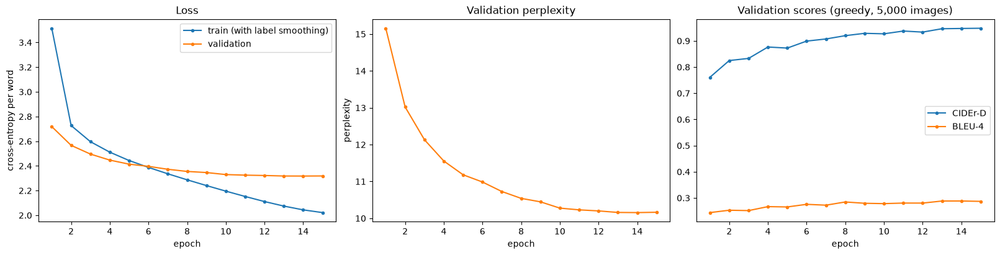

best epoch 15 | val loss 2.318 (perplexity 10.15) | val CIDEr-D 0.948


In [9]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4), constrained_layout=True)
e = xe_hist.index
ax[0].plot(e, xe_hist["train"], marker="o", ms=3, label="train (with label smoothing)")
ax[0].plot(e, xe_hist["val"], marker="o", ms=3, label="validation")
ax[0].set(xlabel="epoch", ylabel="cross-entropy per word", title="Loss"); ax[0].legend()
ax[1].plot(e, np.exp(xe_hist["val"]), marker="o", ms=3, color="C1")
ax[1].set(xlabel="epoch", ylabel="perplexity", title="Validation perplexity")
ax[2].plot(e, xe_hist["cider"], marker="o", ms=3, label="CIDEr-D"); ax[2].plot(e, xe_hist["bleu4"], marker="o", ms=3, label="BLEU-4")
ax[2].set(xlabel="epoch", title="Validation scores (greedy, 5,000 images)"); ax[2].legend()
plt.show()
print(f"best epoch {xe_hist['cider'].idxmax()} | val loss {xe_hist['val'].min():.3f} (perplexity {np.exp(xe_hist['val'].min()):.2f}) "
      f"| val CIDEr-D {xe_hist['cider'].max():.3f}")

**Reading.**
* The training loss falls from 3.52 to 2.02 over the 15 epochs. It includes label smoothing, so only its trend can be compared with the validation loss, not its level.
* The validation loss levels off from epoch 11 (2.325) and reaches its minimum, 2.318, at epochs 13-14 (perplexity 10.1). The model is at the edge of overfitting, not past it.
* CIDEr-D still rises slowly (0.938 to 0.948 over the last five epochs). Selection on CIDEr-D therefore keeps the last epoch.

## Section 9 - Self-critical sequence training

**Motivation.** Cross-entropy trains each word given the reference prefix, but captions are generated from the model's own prefix and judged as whole sentences. SCST (Rennie et al., 2017) fine-tunes the model on the sentence-level metric with REINFORCE.

**Algorithm.**
* For each training image, $K = 5$ captions $w^k$ are sampled.
* Each one receives the reward $r_k$ = CIDEr-D against the image's references, with document frequencies from all `train2017` captions.
* The baseline is the mean reward of the other four samples (Luo, 2020). It needs no extra greedy pass, and the advantages sum to zero within each image.
* The loss is $-\sum_k (r_k - b_k) \log p(w^k)$, averaged over words.

**End token in the reward.** The end token is appended to the sampled caption (when it was emitted) and to every reference. Without it, the policy learns that stopping after a function word ("... on a table with a") costs nothing, because CIDEr-D never sees the missing end: this happened in a first run of the second captioner (Extension E4).

**Optimisation.** Adam, learning rate $5 \cdot 10^{-5}$ (chosen on a pilot, Extension E4), 50 images per batch, dropout off. It starts from the cross-entropy weights. The best validation CIDEr-D is kept, with a patience of 3 epochs.

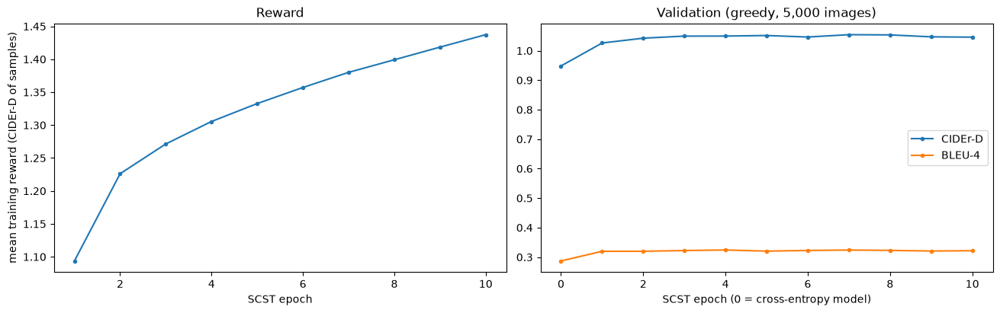

best SCST epoch 7 of 10 | val CIDEr-D 0.948 -> 1.054


In [10]:
def sample_fn(K):
    @tf.function(reduce_retracing=True)
    def sample(f):
        feats = tf.repeat(enc(f), K, axis=0); prep = dec.prepare(feats); n = tf.shape(feats)[0]; st = dec.initial_state(n)
        w = tf.fill([n], START); out = []; alive = tf.ones([n], tf.bool)
        for t in range(T - 1):
            o, st, _ = dec.step(w, feats, prep, st)
            lg = tf.concat([tf.fill([n, 3], -1e9), dec.logits(o)[:, 3:]], -1)
            w = tf.random.categorical(lg, 1, dtype=tf.int32)[:, 0]
            w = tf.where(alive, w, PAD); out.append(w); alive = alive & (w != END)
        return tf.stack(out, 1)
    return sample


def train_scst(cfg, hist, end_token=True):
    K, BI, N = cfg["scst_k"], cfg["scst_batch"], len(train.names)
    EOS = ["</s>"] if end_token else []
    cider_train = Cider([[r + EOS for r in refs] for refs in train.caps], min_df=2)
    opt = keras.optimizers.Adam(cfg["scst_lr"]); sample = sample_fn(K)

    @tf.function(reduce_retracing=True)
    def pg_step(f, s, adv):
        # s: (B*K, T-1) sampled words; adv: (B*K,) advantage
        inp = tf.concat([tf.fill([tf.shape(s)[0], 1], START), s[:, :-1]], 1)
        with tf.GradientTape() as tape:
            feats = tf.repeat(enc(f), K, axis=0); out = decode_teacher(feats, inp, False)
            lg = dec.logits(tf.reshape(out, (-1, out.shape[-1])))
            lg = tf.concat([tf.fill([tf.shape(lg)[0], 3], -1e9), lg[:, 3:]], -1)
            lp = -tf.nn.sparse_softmax_cross_entropy_with_logits(labels=tf.reshape(s, [-1]), logits=lg)
            lp = tf.reshape(lp, tf.shape(s)); mask = tf.cast(s != PAD, tf.float32)
            loss = -tf.reduce_sum(lp * mask * adv[:, None]) / tf.reduce_sum(mask)
        g, _ = tf.clip_by_global_norm(tape.gradient(loss, variables), cfg["clip"])
        opt.apply_gradients(zip(g, variables)); return loss

    best, wait = evaluate()[1], 0; save_npz(RUN_DIR / "scst_best.npz")
    for epoch in range(cfg["scst_epochs"]):
        t0 = time.time(); rs = []; rng = np.random.default_rng(SEED * 100 + 50 + epoch)
        for idx, f in image_batches(train, N, BI, rng):
            s = sample(tf.constant(f)).numpy(); r = np.empty(len(s))
            for j, i in enumerate(idx):
                refs = [cider_train.vec(x + EOS) for x in train.caps[i]]
                for k in range(K):
                    h = ids_to_words(s[j * K + k]); h = h + EOS if END in s[j * K + k] else h
                    r[j * K + k] = cider_train.score_vecs(cider_train.vec(h), refs)
            rr = r.reshape(-1, K); adv = (rr - (rr.sum(1, keepdims=True) - rr) / (K - 1)).ravel()
            pg_step(tf.constant(f), tf.constant(s), tf.constant(adv, tf.float32)); rs.append(r.mean())
        b, c, hyp = evaluate()
        hist.append(dict(phase="scst", epoch=epoch + 1, reward=float(np.mean(rs)), bleu4=b[3], cider=c,
                         words=float(np.mean([len(h) for h in hyp])), sec=time.time() - t0))
        print(json.dumps(hist[-1]), "|", " ".join(hyp[0]))
        if c > best:
            best, wait = c, 0; save_npz(RUN_DIR / "scst_best.npz")
        else:
            wait += 1
        (RUN_DIR / "hist.json").write_text(json.dumps(hist))
        if wait >= cfg["scst_patience"]:
            break


if RETRAIN or not (RUN_DIR / "scst_best.npz").exists():
    load_npz(RUN_DIR / "xe_best.npz"); train_scst(CFG, hist)
load_npz(RUN_DIR / "scst_best.npz")

sc = [x for x in hist if x["phase"] == "scst"]; xe_best = xe_hist["cider"].max()
fig, ax = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)
ax[0].plot([x["epoch"] for x in sc], [x["reward"] for x in sc], marker="o", ms=3)
ax[0].set(xlabel="SCST epoch", ylabel="mean training reward (CIDEr-D of samples)", title="Reward")
ax[1].plot([0] + [x["epoch"] for x in sc], [xe_best] + [x["cider"] for x in sc], marker="o", ms=3, label="CIDEr-D")
ax[1].plot([0] + [x["epoch"] for x in sc], [xe_hist["bleu4"][xe_hist["cider"].idxmax()]] + [x["bleu4"] for x in sc], marker="o", ms=3, label="BLEU-4")
ax[1].set(xlabel="SCST epoch (0 = cross-entropy model)", title="Validation (greedy, 5,000 images)"); ax[1].legend()
plt.show()
best_sc = max(sc, key=lambda x: x["cider"])
print(f"best SCST epoch {best_sc['epoch']} of {len(sc)} | val CIDEr-D {xe_best:.3f} -> {best_sc['cider']:.3f}")

**Reading.**
* SCST raises the validation CIDEr-D from 0.948 to 1.054 (+11 %), most of it in the first epoch. BLEU-4 rises with it (0.287 to 0.32), so the gain is not specific to the reward metric.
* The training reward keeps rising up to the tenth epoch (1.09 to 1.44), while the validation score is flat from the third. The later gains fit the training captions only, and the best validation epoch (7) is kept.

## Section 10 - Test examples and evaluation

**Decoding.** Beam search over the incremental decoder:
* `<pad>`, `<unk>` and `<start>` are never emitted, and a finished beam keeps its score.
* The final choice optionally divides the log-probability by the length penalty $((5 + |y|)/6)^{\alpha}$ (Wu et al., 2016).
* The width and $\alpha$ are chosen on validation CIDEr-D.

**Metrics.**
* **Captioning metrics.** BLEU-1 to 4, METEOR, ROUGE-L, CIDEr-D and SPICE from `pycocoevalcap`, with PTB tokenisation, on all 5,000 `val2017` images.
* **CLIPScore** (Hessel et al., 2021, CLIP ViT-B/32): $2.5 \max(\cos(\text{image}, \text{caption}), 0)$. It needs no references, which makes `test2017` usable. RefCLIPScore also uses the references, on `val2017`.
* **Human level.** The first human caption of each image is scored against the others.

**Selection on validation.** `val2017` also served for checkpoint selection and the choice of decoding, so its scores are slightly optimistic. `test2017` plays no role in any choice.

**Cached results.** Every result is stored in the run's `eval` folder and recomputed only when missing.

In [11]:
def beam_search(features, width=3, length_power=0.0):
    """Beam search for a batch. Returns word-id sequences (B, T-1) and the attention of the chosen beam (B, T-1, R)."""
    B, K = len(features), width
    feats = tf.repeat(enc(tf.constant(features, tf.float32)), K, axis=0); prep = dec.prepare(feats)
    state = dec.initial_state(B * K); R_ = int(feats.shape[1])
    scores = np.full((B, K), -np.inf); scores[:, 0] = 0.0
    seqs = np.zeros((B, K, T - 1), np.int32); att = np.zeros((B, K, T - 1, R_), np.float32)
    done = np.zeros((B, K), bool); last = np.full(B * K, START, np.int32)
    for t in range(T - 1):
        lp, state, a = decoder_step(tf.constant(last), feats, prep, state)
        lp = lp.numpy().reshape(B, K, -1)
        lp[:, :, [PAD, UNK, START]] = -np.inf
        lp[done] = -np.inf; lp[:, :, PAD][done] = 0.0                  # a finished beam keeps its score
        Vn = lp.shape[-1]
        cand = (scores[:, :, None] + lp).reshape(B, -1)
        top = np.argsort(-cand, axis=1)[:, :K]
        scores = np.take_along_axis(cand, top, 1); beam, word = top // Vn, (top % Vn).astype(np.int32)
        seqs = np.take_along_axis(seqs, beam[:, :, None], 1); att = np.take_along_axis(att, beam[:, :, None, None], 1)
        seqs[:, :, t] = word
        chosen = (np.arange(B)[:, None] * K + beam).ravel()
        att[:, :, t] = a.numpy()[chosen, :, 0].reshape(B, K, R_)
        done = np.take_along_axis(done, beam, 1) | (word == END) | (word == PAD)
        state = tuple(tf.gather(s, chosen) for s in state); last = word.ravel()
        if done.all():
            break
    lengths = np.maximum(((seqs != PAD) & (seqs != END)).sum(-1), 1)
    best = (scores / (((5 + lengths) / 6.0) ** length_power)).argmax(1)
    rows = np.arange(B)
    return seqs[rows, best], att[rows, best]


def caption(store, n, width, power, batch=100):
    out = []
    for s in range(0, n, batch):
        ids, _ = beam_search(store.features(s, min(s + batch, n)), width, power)
        out += [" ".join(ids_to_words(r)) for r in ids]
    return out


def cached(stage, fn):
    p = E / f"{stage}.json"
    if p.exists() and not RETRAIN:
        return json.loads(p.read_text())
    r = fn(); p.write_text(json.dumps(r)); return r


def decoding_grid():
    load_npz(weights["scst"]); rows = []
    for width, power in [(1, 0.0), (3, 0.0), (5, 0.0), (3, 1.0), (5, 1.0)]:
        hyp = [h.split() for h in caption(val, NV, width, power)]
        rows.append({"width": width, "power": power, "cider": cider_d(val.caps, hyp)[0], "bleu4": bleu(val.caps, hyp)[3],
                     "words": float(np.mean([len(h) for h in hyp]))})
    return rows


def captions_of(m, store):
    load_npz(weights[m]); return caption(store, len(store.names), W, P)


grid = cached("decoding", decoding_grid)
display(pd.DataFrame(grid).rename(columns={"power": "length penalty alpha", "cider": "val CIDEr-D", "bleu4": "val BLEU-4"})
        .round(4).style.hide(axis="index"))
bestdec = max(grid, key=lambda r: r["cider"]); W, P = bestdec["width"], bestdec["power"]
print(f"decoding used below: beam width {W}, length penalty alpha {P}")
val_caps = {m: cached(f"val_captions_{m}", lambda m=m: captions_of(m, val)) for m in weights}
test_caps = cached("test_captions", lambda: captions_of("scst", test))
load_npz(weights["scst"])

width,length penalty alpha,val CIDEr-D,val BLEU-4,words
1,0.000000,1.054400,0.323900,9.427200
3,0.000000,1.055600,0.325000,9.374000
5,0.000000,1.055800,0.325200,9.368800
3,1.000000,1.055100,0.323700,9.440000
5,1.000000,1.055500,0.323900,9.441200


decoding used below: beam width 5, length penalty alpha 0.0


In [12]:
def coco_metrics(m):
    """Official COCO caption metrics (pycocoevalcap, PTB tokenisation; METEOR and SPICE run on Java)."""
    os.environ["PATH"] = "/home/zakar/opt/jdk8u504-b01-jre/bin:" + os.environ["PATH"]
    from pycocoevalcap.tokenizer.ptbtokenizer import PTBTokenizer
    from pycocoevalcap.bleu.bleu import Bleu
    from pycocoevalcap.meteor.meteor import Meteor
    from pycocoevalcap.rouge.rouge import Rouge
    from pycocoevalcap.cider.cider import Cider as CiderEval
    from pycocoevalcap.spice.spice import Spice
    gts = {i: [{"caption": c} for c in val.raw[i]] for i in range(NV)}
    res = {i: [{"caption": c}] for i, c in enumerate(val_caps[m])}
    tok = PTBTokenizer(); gts, res = tok.tokenize(gts), tok.tokenize(res)
    out = {}
    for scorer, names in [(Bleu(4), ["BLEU-1", "BLEU-2", "BLEU-3", "BLEU-4"]), (Meteor(), ["METEOR"]), (Rouge(), ["ROUGE-L"]),
                          (CiderEval(), ["CIDEr-D"]), (Spice(), ["SPICE"])]:
        s, _ = scorer.compute_score(gts, res)
        for k, v in zip(names, s if isinstance(s, list) else [s]):
            out[k] = float(v)
    return out


DANGLING = {"a", "an", "the", "of", "with", "on", "and", "in", "to", "at", "its", "his", "her", "their", "next", "from", "by", "for"}


def dangling(caps):
    """Share of captions whose last word is an article, preposition, conjunction or possessive."""
    return float(np.mean([c.split()[-1] in DANGLING for c in caps if c]))


metrics = {m: cached(f"coco_metrics_{m}", lambda m=m: coco_metrics(m)) for m in weights}
table = pd.DataFrame({"cross-entropy": metrics["xe"], "SCST (final)": metrics["scst"]}).T
table["truncated endings"] = [dangling(val_caps["xe"]), dangling(val_caps["scst"])]
table["words per caption"] = [np.mean([len(c.split()) for c in val_caps[m]]) for m in ("xe", "scst")]
display(table.style.format("{:.3f}"))
print(f"human captions: truncated endings {dangling([r[0] for r in val.raw if r]):.3f}, "
      f"{np.mean([len(c) for c in val.caps for c in c]):.1f} words per caption")

,BLEU-1,BLEU-2,BLEU-3,BLEU-4,METEOR,ROUGE-L,CIDEr-D,SPICE,truncated endings,words per caption
cross-entropy,0.716,0.543,0.408,0.309,0.252,0.528,0.971,0.182,0.001,9.295
SCST (final),0.747,0.580,0.436,0.325,0.255,0.542,1.056,0.192,0.000,9.369


human captions: truncated endings 0.002, 10.4 words per caption


In [13]:
CLIP_PRESET = "clip_vit_base_patch32"
_clip = {}


def clip_model():
    if not _clip:
        import keras_hub
        _clip["pp"] = keras_hub.models.CLIPPreprocessor.from_preset(CLIP_PRESET); _clip["pp"].build(None)
        _clip["m"] = keras_hub.models.CLIPBackbone.from_preset(CLIP_PRESET)
    return _clip["pp"], _clip["m"]


def clip_image(path, size=224):
    # CLIP preparation: shorter side to 224 (bicubic), centre crop
    img = Image.open(path).convert("RGB"); w, h = img.size; s = size / min(w, h)
    img = img.resize((max(size, round(w * s)), max(size, round(h * s))), Image.BICUBIC)
    w, h = img.size; l, t = (w - size) // 2, (h - size) // 2
    return np.asarray(img.crop((l, t, l + size, t + size)), dtype=np.float32)


def image_embeddings(paths, batch=64):
    pp, m = clip_model(); conv = pp.image_converter
    scale, offset = np.array(conv.scale, np.float32), np.array(conv.offset, np.float32)
    out = []
    for s in range(0, len(paths), batch):
        e = m.get_vision_embeddings(tf.constant(np.stack([clip_image(p) for p in paths[s:s + batch]]) * scale + offset)).numpy()
        out.append(e / np.linalg.norm(e, axis=1, keepdims=True))
    return np.concatenate(out)


def text_embeddings(texts, batch=256, prompt="A photo depicts "):
    pp, m = clip_model(); out = []
    for s in range(0, len(texts), batch):
        tok = pp.packer(pp.tokenizer([prompt + t for t in texts[s:s + batch]]))
        e = m.get_text_embeddings(tok[0] if isinstance(tok, tuple) else tok["token_ids"]).numpy()
        out.append(e / np.linalg.norm(e, axis=1, keepdims=True))
    return np.concatenate(out)


def clip_s(img_emb, cap_emb, w=2.5):
    return w * np.maximum((img_emb * cap_emb).sum(1), 0.0)


def ref_clip_s(img_emb, cap_emb, ref_embs, w=2.5):
    # harmonic mean of CLIP-S and the best cosine with a reference
    c = clip_s(img_emb, cap_emb, w)
    r = np.array([max(float((refs @ e).max()), 0.0) for refs, e in zip(ref_embs, cap_emb)])
    return np.where(c + r > 0, 2 * c * r / np.maximum(c + r, 1e-12), 0.0)


# gender-neutral rewriting, used for publication (Extension E3)
NEUTRAL = {"man": "person", "woman": "person", "men": "people", "women": "people", "boy": "child", "girl": "child",
           "boys": "children", "girls": "children", "guy": "person", "guys": "people", "lady": "person", "ladies": "people",
           "gentleman": "person", "gentlemen": "people", "male": "person", "female": "person", "males": "people", "females": "people",
           "he": "they", "she": "they", "his": "their", "her": "their", "him": "them", "himself": "themselves", "herself": "themselves",
           "father": "parent", "mother": "parent", "son": "child", "daughter": "child", "husband": "partner", "wife": "partner",
           "brother": "sibling", "sister": "sibling", "businessman": "businessperson", "businesswoman": "businessperson",
           "policeman": "police officer", "policewoman": "police officer", "fireman": "firefighter", "dad": "parent", "mom": "parent"}


def neutralise(words_):
    return " ".join(NEUTRAL.get(w, w) for w in words_).split()


def clip_scores():
    """CLIPScore of every caption set on val2017 and of the final model on test2017; RefCLIPScore on val2017."""
    vimg = image_embeddings([val.path(i) for i in range(NV)])
    flat = [c for rs in val.raw for c in rs]; emb = text_embeddings(flat); ref_embs, k = [], 0
    for rs in val.raw:
        ref_embs.append(emb[k:k + len(rs)]); k += len(rs)
    first = np.stack([r[0] for r in ref_embs])
    out = {"human_val": {"CLIP-S": float(clip_s(vimg, first).mean()),
                         "RefCLIP-S": float(ref_clip_s(vimg, first, [r[1:] for r in ref_embs]).mean())}}
    for m in weights:
        for suffix, caps in [("", val_caps[m]), ("_neutral", [" ".join(neutralise(c.split())) for c in val_caps[m]])]:
            e = text_embeddings(caps)
            out[f"{m}_val{suffix}"] = {"CLIP-S": float(clip_s(vimg, e).mean()), "RefCLIP-S": float(ref_clip_s(vimg, e, ref_embs).mean())}
    s = np.concatenate([clip_s(image_embeddings([test.path(i) for i in range(a, min(a + 2000, len(test.names)))]),
                                  text_embeddings(test_caps[a:a + 2000])) for a in range(0, len(test_caps), 2000)])
    np.save(E / "test_clip_s.npy", s)
    out["final_test"] = {"CLIP-S": float(s.mean()), "images": int(len(s)),
                         "CI95": [float(np.percentile(np.random.default_rng(0).choice(s, (300, len(s))).mean(1), q)) for q in (2.5, 97.5)]}
    return out


clip = cached("clip", clip_scores)
display(pd.DataFrame({"human (first reference)": clip["human_val"], "cross-entropy": clip["xe_val"],
                      "SCST (final)": clip["scst_val"]}).T.style.format("{:.3f}"))
ft = clip["final_test"]
print(f"test2017, final model: CLIP-S {ft['CLIP-S']:.3f} on {ft['images']:,d} images "
      f"(bootstrap 95% interval {ft['CI95'][0]:.3f} to {ft['CI95'][1]:.3f})")

,CLIP-S,RefCLIP-S
human (first reference),0.777,0.819
cross-entropy,0.717,0.779
SCST (final),0.719,0.781


test2017, final model: CLIP-S 0.722 on 40,670 images (bootstrap 95% interval 0.721 to 0.723)


**Reading.**
* **Decoding.** Beam search adds only 0.001 CIDEr-D over greedy decoding, and the length penalty has no effect. After SCST, the distribution of each word is sharp, so the beam rarely finds a better sentence. Width 5 with $\alpha = 0$ is kept.
* **Metrics.** SCST improves all of the official metrics, including those it does not optimise (METEOR +0.003, SPICE +0.010). It also removes the truncated endings.
* **CLIPScore.** The reference-free score barely moves with SCST (0.717 to 0.719), while CIDEr-D gains 0.085. SCST improves the agreement of the wording with the references more than the description of the image. Human captions score 0.777: the model's captions are correct but more generic.
* **Test set.** On `test2017` the score is 0.722 (95 % interval 0.721-0.723), as on `val2017`. The selection on `val2017` did not overfit it.

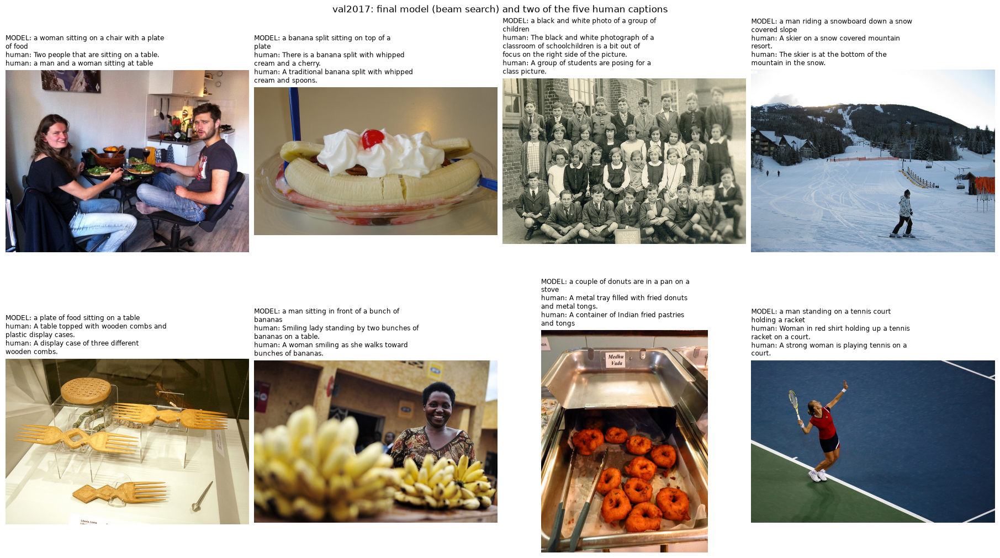

In [14]:
# 10.1 validation examples: the final caption against two human captions
fig, axes = plt.subplots(2, 4, figsize=(18, 10), constrained_layout=True)
for ax, i in zip(axes.ravel(), range(8)):
    ax.imshow(Image.open(val.path(i)).convert("RGB")); ax.axis("off")
    ax.set_title(textwrap.fill("MODEL: " + val_caps["scst"][i], 46) + "\n" +
                 "\n".join(textwrap.fill("human: " + c, 46) for c in val.raw[i][:2]), fontsize=8.5, loc="left")
plt.suptitle("val2017: final model (beam search) and two of the five human captions", fontsize=12)
plt.show()

captions identical to the cached test2017 captions: 8 / 8


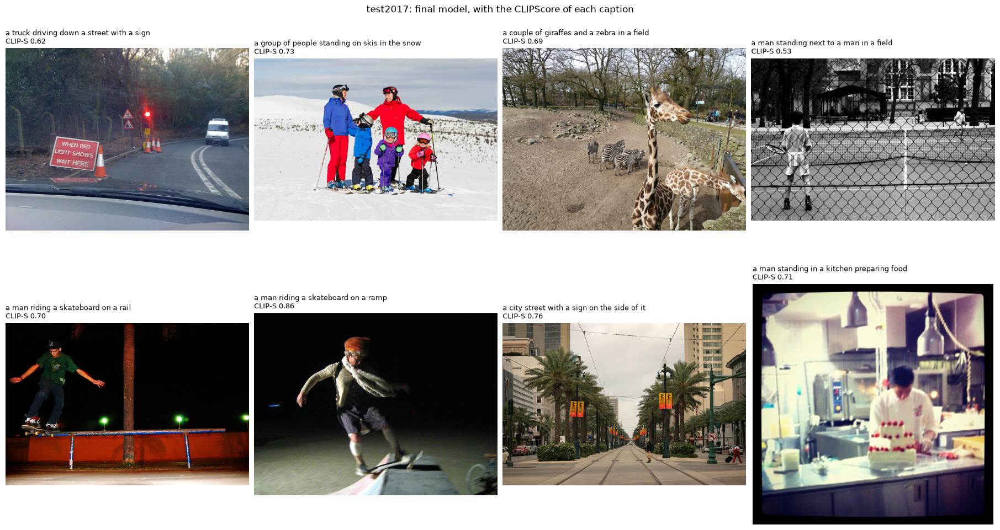

In [15]:
# 10.2 test2017 images (no public captions): decoded and encoded from the image files with the pre-processing of Section 4
def caption_files(paths, width=W, power=P):
    feats = extractor(MODELS[CUR]["cnn"])["extract"](paths)
    ids, att = beam_search(feats, width, power)
    return [" ".join(ids_to_words(r)) for r in ids], ids, att


picks = list(range(100, 108))
caps, ids, att = caption_files([test.path(i) for i in picks])
test_clip = np.load(E / "test_clip_s.npy")
print(f"captions identical to the cached test2017 captions: {sum(c == test_caps[i] for c, i in zip(caps, picks))} / {len(picks)}")
fig, axes = plt.subplots(2, 4, figsize=(18, 9.5), constrained_layout=True)
for ax, i, c in zip(axes.ravel(), picks, caps):
    ax.imshow(Image.open(test.path(i)).convert("RGB")); ax.axis("off")
    ax.set_title(textwrap.fill(c, 46) + f"\nCLIP-S {test_clip[i]:.2f}", fontsize=9, loc="left")
plt.suptitle("test2017: final model, with the CLIPScore of each caption", fontsize=12)
plt.show()

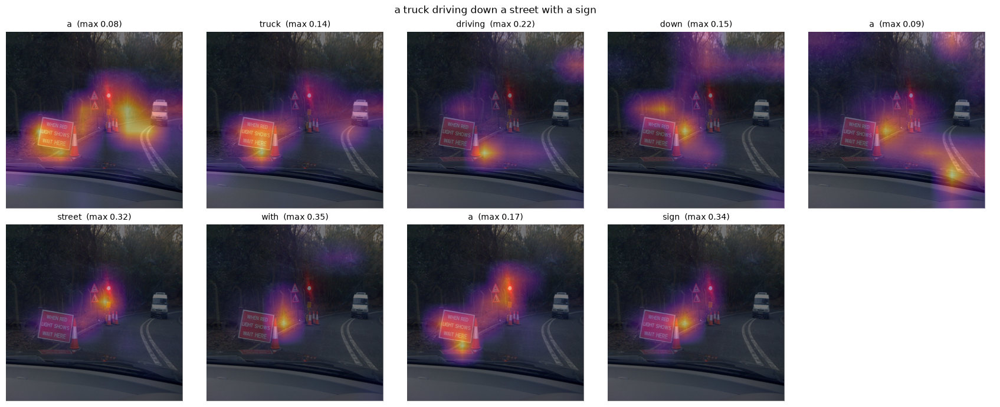

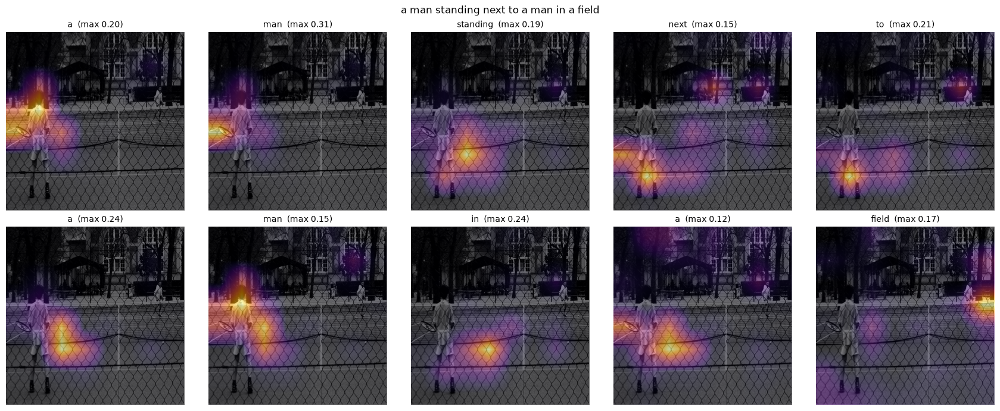

attention entropy per word: median 2.88 nats (uniform over 64 regions: 4.16)


In [16]:
# 10.3 attention weights over the 8 x 8 InceptionV3 regions for each generated word
def plot_attention(path, ids_row, att_row, columns=5):
    size = CNNS[MODELS[CUR]["cnn"]][1]
    img = np.asarray(Image.open(path).convert("RGB").resize((size, size)))
    toks = ids_to_words(ids_row); side = int(round(att_row.shape[1] ** 0.5))
    rows = math.ceil(len(toks) / columns)
    fig, axes = plt.subplots(rows, columns, figsize=(3.4 * columns, 3.4 * rows), constrained_layout=True)
    for ax in axes.ravel():
        ax.axis("off")
    for t, (ax, wd) in enumerate(zip(axes.ravel(), toks)):
        a = att_row[t].reshape(side, side)
        ax.imshow(img); ax.imshow(a, cmap="inferno", alpha=0.55, extent=(0, size, size, 0), interpolation="bilinear")
        ax.set_title(f"{wd}  (max {a.max():.2f})", fontsize=10)
    plt.suptitle(" ".join(toks), fontsize=12)
    plt.show()


for j in (0, 3):
    plot_attention(test.path(picks[j]), ids[j], att[j])
ent = [-(a[:len(ids_to_words(r))] * np.log(a[:len(ids_to_words(r))] + 1e-12)).sum(-1) for r, a in zip(ids, att)]
print(f"attention entropy per word: median {np.median(np.concatenate(ent)):.2f} nats (uniform over 64 regions: {math.log(64):.2f})")

**Reading.**
* **What is right.** The scene and the main objects are correct in most examples (banana split, fried pastries in a tray, ski slope, tennis court). The model also recognises that the class photograph is black and white.
* **Typical errors.**
  * Fine distinctions: snowboard instead of skis.
  * Counting and relations: "a man standing next to a man", "a couple of giraffes and a zebra".
  * Gender: two of the eight validation images show a woman described as a man (bananas, tennis). Extension E3 measures this error.
* **Attention.** Content words such as "driving", "street" and "sign" concentrate on a few regions around the road and the signs (maximum weight 0.22 to 0.35). The articles spread their weight (maximum 0.08 to 0.17).
* **Entropy.** The median, 2.88 nats, corresponds to about $e^{2.88} \approx 18$ effective regions out of 64. Attention selects, but coarsely, which is expected from an 8 x 8 grid where each cell covers about 37 pixels of the 299-pixel input.

## Section 11 - Saving the captioner

**Contents.** The captioner is saved next to this notebook in `leyenda_captioner_gru/`:
* the encoder and decoder weights (`encoder.weights.h5`, `decoder.weights.h5`);
* the vocabulary (`vocab.json`), which must stay paired with the weights;
* the configuration (`config.json`): dimensions, caption length, CNN, input size and decoding settings.

**New images** need the pre-processing of Section 4 (InceptionV3, 299 x 299), applied by `caption_files` and by the workflow of Section 12.

**Check.** The model is rebuilt from these files alone and must reproduce the captions of the trained model exactly on 16 validation images.

In [17]:
NET_KEYS = {"gru": ("emb", "enc", "units", "dropout", "enc_drop"), "transformer": ("d", "enc_layers", "dec_layers", "heads", "ff", "dropout")}


def save_captioner(name):
    folder = MODELS[name]["save"]; folder.mkdir(parents=True, exist_ok=True)
    enc.save_weights(str(folder / "encoder.weights.h5")); dec.save_weights(str(folder / "decoder.weights.h5"))
    (folder / "vocab.json").write_text(json.dumps(words))
    (folder / "config.json").write_text(json.dumps({"model": name, **{k: CFG[k] for k in NET_KEYS[name]}, "T": T,
                                                     "regions": GRID[MODELS[name]["cnn"]][0], "features": D, "backbone": MODELS[name]["cnn"],
                                                     "image_size": CNNS[MODELS[name]["cnn"]][1], "beam_width": W, "length_power": P}, indent=2))


def load_captioner(folder):
    """Rebuilds a captioner from its saved files (no training data needed) and makes it the current model."""
    global enc, dec, words, V, greedy, decoder_step, W, P, CUR
    cfg = json.loads((folder / "config.json").read_text()); words = json.loads((folder / "vocab.json").read_text()); V = len(words)
    enc, dec = (build_gru if cfg.get("model", "transformer") == "gru" else build_transformer)(cfg, V, cfg["regions"])
    enc.load_weights(str(folder / "encoder.weights.h5")); dec.load_weights(str(folder / "decoder.weights.h5"))
    greedy = tf.function(_greedy, reduce_retracing=True); decoder_step = tf.function(_decoder_step, reduce_retracing=True)
    W, P, CUR = cfg["beam_width"], cfg["length_power"], cfg.get("model", "transformer")
    for s in (train, val, test):
        s.use(cfg["backbone"] if cfg["backbone"] in GRID else "convnext")
    return cfg


before = caption(val, 16, W, P)
save_captioner("gru")
gru_cfg = load_captioner(MODELS["gru"]["save"])
after = caption(val, 16, W, P)
folder = MODELS["gru"]["save"]
print("saved in:", folder, "|", sorted(p.name for p in folder.iterdir()),
      f"| {sum(p.stat().st_size for p in folder.iterdir()) / 1e6:.1f} MB")
print(f"identical captions before and after reloading: {sum(a == b for a, b in zip(before, after))} / {len(before)}")
assert before == after, "the reloaded captioner does not match the trained one"

saved in: /mnt/c/Users/zakar/OneDrive/Desktop/CESI Learning/deliverable3/leyenda_captioner_gru | ['config.json', 'decoder.weights.h5', 'encoder.weights.h5', 'vocab.json'] | 73.5 MB
identical captions before and after reloading: 16 / 16


## Section 12 - The complete workflow: from an unidentified image to a captioned photograph

For any incoming image, the three saved models are chained without retraining:

1. **Reading** as RGB, with the longest side limited to `MAX_SIDE` pixels.
2. **Deliverable 2, denoising.** The residual-block U-Net (`denoiser_coco.keras`, the first-stage model of Deliverable 2; the test website uses its fine-tuned version `denoiser_coco_v2.keras`) is applied at the image's own size, in overlapping tiles. Deliverable 2 showed that it leaves clean images unchanged (59.6 dB), so no noise detector is needed in front of it.
3. **Deliverable 1, photo gate.** The binary CNN (`modele_photo.keras`, input 180 x 180) gives P(photo). Below 0.5 the processing stops: documents, schematics, sketches and paintings are not captioned.
4. **Deliverable 3, captioning.** InceptionV3 encodes the photograph (Section 4) and the captioner reloaded from `leyenda_captioner_gru/` writes the caption.

**Order of the chain.** Deliverable 2 placed the denoiser after the gate. It comes first here because of the measurement of Extension E2: the gate rejects most noisy photographs when it sees them directly, and accepts them again once they are denoised.

**Batch use.** `process_folder` applies the chain to every image of a folder and writes one line per image (file, P(photo), decision, caption) to a CSV file, which is the form in which TouNum would run it on an archive.

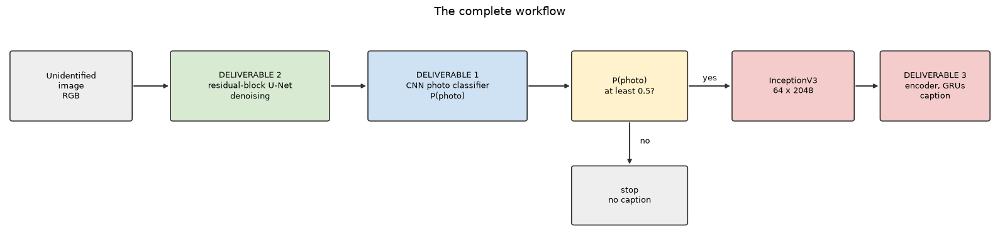

Deliverable 1 classifier: input (180, 180, 3), 1,175,393 weights
Deliverable 2 denoiser: 32,653,059 weights | Deliverable 3 captioner: 18,330,369 weights + InceptionV3


Using 8138 files for validation.


Deliverable 1 test images: {'Painting': 1989, 'Photo': 2024, 'Schematics': 1922, 'Sketch': 267, 'Text': 1936}


In [18]:
def draw_workflow():
    fig, ax = plt.subplots(figsize=(16, 4.1))
    ax.set_xlim(0, 16); ax.set_ylim(0, 4.1); ax.axis("off")

    def box(x, y, w, h, text, color):
        ax.add_patch(mpatches.FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.04", fc=color, ec="#333333", lw=1.2))
        ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=9.5)

    def arrow(p, q, label=None, at=(0, 0.1)):
        ax.annotate("", xy=q, xytext=p, arrowprops=dict(arrowstyle="-|>", lw=1.4, color="#333333"))
        if label:
            ax.text((p[0] + q[0]) / 2 + at[0], (p[1] + q[1]) / 2 + at[1], label, fontsize=9, ha="center")

    box(0.1, 2.3, 1.9, 1.2, "Unidentified\nimage\nRGB", "#eeeeee")
    box(2.7, 2.3, 2.5, 1.2, "DELIVERABLE 2\nresidual-block U-Net\ndenoising", "#d9ead3")
    box(5.9, 2.3, 2.5, 1.2, "DELIVERABLE 1\nCNN photo classifier\nP(photo)", "#cfe2f3")
    box(9.2, 2.3, 1.8, 1.2, "P(photo)\nat least 0.5?", "#fff2cc")
    box(11.8, 2.3, 1.9, 1.2, "InceptionV3\n64 x 2048", "#f4cccc")
    box(14.2, 2.3, 1.7, 1.2, "DELIVERABLE 3\nencoder, GRUs\ncaption", "#f4cccc")
    box(9.2, 0.4, 1.8, 1.0, "stop\nno caption", "#eeeeee")
    arrow((2.04, 2.9), (2.66, 2.9)); arrow((5.24, 2.9), (5.86, 2.9)); arrow((8.44, 2.9), (9.16, 2.9))
    arrow((11.04, 2.9), (11.76, 2.9), "yes"); arrow((13.74, 2.9), (14.16, 2.9))
    arrow((10.1, 2.26), (10.1, 1.44), "no", at=(0.25, 0))
    plt.title("The complete workflow", fontsize=13); plt.tight_layout(); plt.show()


draw_workflow()

classifier = keras.models.load_model(D1_MODEL, compile=False)
denoiser = keras.models.load_model(D2_MODEL, compile=False)
print(f"Deliverable 1 classifier: input {classifier.input_shape[1:]}, {classifier.count_params():,} weights")
print(f"Deliverable 2 denoiser: {denoiser.count_params():,} weights | Deliverable 3 captioner: {n_params(enc, dec):,} weights + InceptionV3")

MAX_SIDE, PHOTO_THRESHOLD, TILE, MARGIN = 1024, 0.5, 256, 64
denoise_tiles = tf.function(lambda x: denoiser(x, training=False), reduce_retracing=True)


def read_image(path):
    # file -> float32 RGB image in [0, 1], longest side limited to MAX_SIDE
    img = Image.open(path).convert("RGB")
    img.thumbnail((MAX_SIDE, MAX_SIDE), Image.LANCZOS)
    return np.asarray(img, dtype=np.float32) / 255.0


def denoise(img, batch=8):
    # same inference as Deliverable 2: 256 x 256 tiles with 64 pixels of reflected context, batched
    h, w = img.shape[:2]; H, W_ = h + -h % TILE, w + -w % TILE
    x = np.pad(img, ((MARGIN, MARGIN + H - h), (MARGIN, MARGIN + W_ - w), (0, 0)), mode="reflect")
    corners = [(i, j) for i in range(0, H, TILE) for j in range(0, W_, TILE)]
    out = np.empty((H, W_, 3), np.float32)
    for s in range(0, len(corners), batch):
        part = corners[s:s + batch]
        y = denoise_tiles(tf.constant(np.stack([x[i:i + TILE + 2 * MARGIN, j:j + TILE + 2 * MARGIN] for i, j in part]))).numpy()
        for (i, j), t in zip(part, y):
            out[i:i + TILE, j:j + TILE] = t[MARGIN:MARGIN + TILE, MARGIN:MARGIN + TILE]
    return np.clip(out[:h, :w], 0.0, 1.0)


def photo_probability(img):
    # same preparation as Deliverable 1: bilinear resize to 180 x 180, values 0-255
    x = tf.image.resize(tf.constant(img * 255.0), classifier.input_shape[1:3], method="bilinear")
    return float(classifier(x[None], training=False)[0, 0])


def image_features(img):
    # same pre-processing as Section 4, from an array in [0, 1]
    x = extractor("inception")
    return x["net"](tf.image.resize(tf.constant(img * 255.0), (x["size"], x["size"]))[None]).numpy().astype(np.float32)


def caption_features(feats):
    ids, _ = beam_search(feats, W, P)
    return [" ".join(ids_to_words(r)) for r in ids]


def process_image(image, name="image"):
    # image: a path, or a float array in [0, 1]. Runs the whole chain.
    img = read_image(image) if isinstance(image, (str, Path)) else image
    cleaned = denoise(img)
    p_photo = photo_probability(cleaned)
    is_photo = p_photo >= PHOTO_THRESHOLD
    text = caption_features(image_features(cleaned))[0] if is_photo else None
    return {"name": name, "input": img, "denoised": cleaned, "P(photo)": p_photo, "photo": is_photo, "caption": text}


def process_folder(folder, output_csv):
    # applies the chain to every image of a folder and writes one line per image
    files = sorted(p for p in Path(folder).iterdir() if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"})
    results = [process_image(p, p.name) for p in files]
    table = pd.DataFrame([{k: r[k] for k in ("name", "P(photo)", "photo", "caption")} for r in results])
    table.to_csv(output_csv, index=False)
    return table, results


# the test split of Deliverable 1: same call, same seed, so none of these images trained the classifier
d1_test = keras.utils.image_dataset_from_directory(D1_DATA, validation_split=0.2, subset="validation", seed=42,
                                                   image_size=(180, 180), batch_size=32, verbose=False)
d1_files = collections.defaultdict(list)
for f_ in d1_test.file_paths:
    d1_files[Path(f_).parent.name].append(f_)
print("Deliverable 1 test images:", {k: len(v) for k, v in sorted(d1_files.items())})

**Demonstration.** A folder of inputs the captioning network never saw: three photographs of `test2017`, one with Gaussian noise (sigma = 50/255), one with 5 % salt and pepper noise, and one Deliverable 1 test image of each non-photo class, drawn with a fixed seed. The folder is processed in one call and the CSV is displayed.

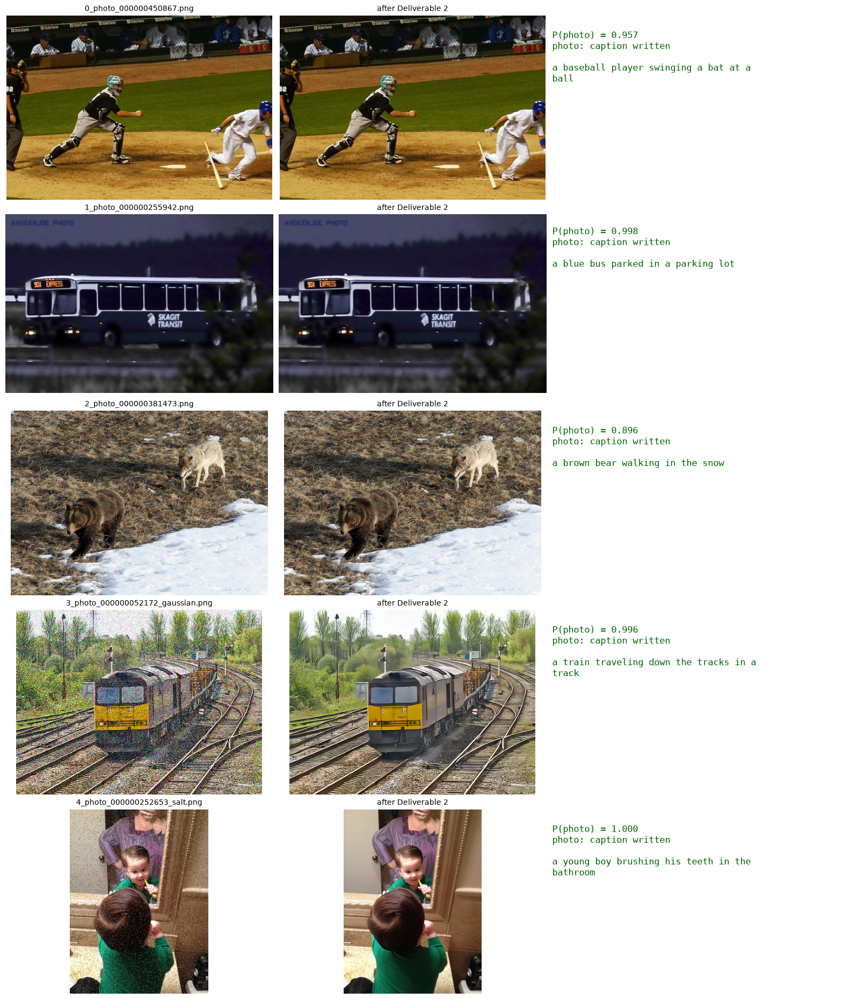

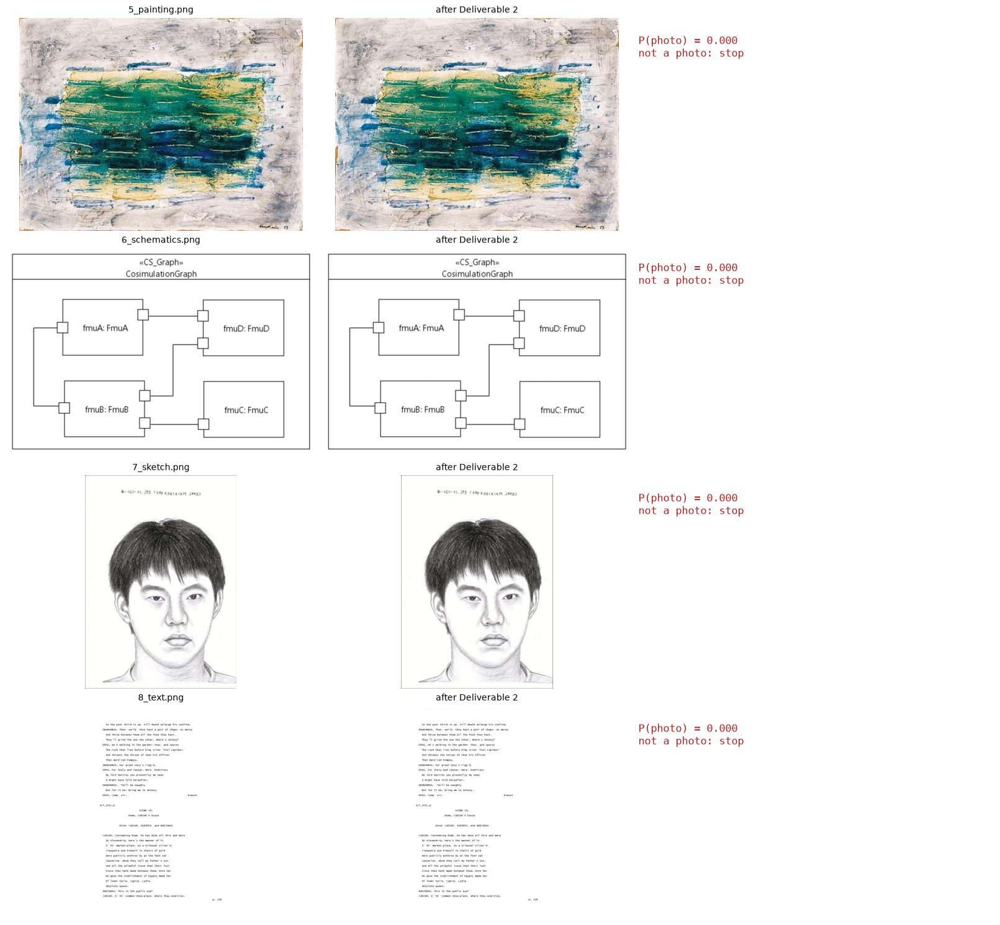

written: /mnt/c/Users/zakar/OneDrive/Desktop/CESI Learning/deliverable3/workflow_demo/captions.csv


,name,P(photo),photo,caption
0,0_photo_000000450867.png,0.957,True,a baseball player swinging a bat at a ball
1,1_photo_000000255942.png,0.998,True,a blue bus parked in a parking lot
2,2_photo_000000381473.png,0.896,True,a brown bear walking in the snow
3,3_photo_000000052172_gaussian.png,0.996,True,a train traveling down the tracks in a track
4,4_photo_000000252653_salt.png,1.000,True,a young boy brushing his teeth in the bathroom
5,5_painting.png,0.000,False,NaN
6,6_schematics.png,0.000,False,NaN
7,7_sketch.png,0.000,False,NaN
8,8_text.png,0.000,False,NaN


In [19]:
def add_noise(img, kind, level, seed):
    # same noise models as Deliverable 2. img: float32 (H, W, 3) in [0, 1]
    rng = np.random.default_rng(seed)
    if kind == "gaussian":
        out = img + level * rng.standard_normal(img.shape, dtype=np.float32)
    elif kind == "salt_pepper":
        u = rng.random(img.shape[:2], dtype=np.float32)[:, :, None]
        out = np.where(u < level / 2, 0.0, np.where(u > 1 - level / 2, 1.0, img))
    elif kind == "speckle":
        out = img + img * level * rng.standard_normal(img.shape, dtype=np.float32)
    elif kind == "poisson":
        out = rng.poisson(img * level).astype(np.float32) / level
    else:
        raise ValueError(kind)
    return np.clip(out, 0.0, 1.0).astype(np.float32)


CONDITIONS = {"gaussian 25": ("gaussian", 25 / 255), "gaussian 50": ("gaussian", 50 / 255),
              "salt & pepper 5%": ("salt_pepper", 0.05), "speckle 0.2": ("speckle", 0.2), "poisson peak 20": ("poisson", 20.0)}


def show_chain(results):
    fig, axes = plt.subplots(len(results), 3, figsize=(16, 3.7 * len(results)), gridspec_kw={"width_ratios": [1, 1, 1.15]}, constrained_layout=True)
    for (a_in, a_out, a_txt), r in zip(np.atleast_2d(axes), results):
        a_in.imshow(r["input"]); a_in.set_title(r["name"], fontsize=10); a_in.axis("off")
        a_out.imshow(r["denoised"]); a_out.set_title("after Deliverable 2", fontsize=10); a_out.axis("off")
        lines = [f"P(photo) = {r['P(photo)']:.3f}", "photo: caption written" if r["photo"] else "not a photo: stop", ""]
        lines += textwrap.wrap(r["caption"], 40) if r["photo"] else []
        a_txt.axis("off")
        a_txt.text(0.0, 0.92, "\n".join(lines), va="top", fontsize=12, family="monospace", color="darkgreen" if r["photo"] else "firebrick")
    plt.show()


demo_dir = PROJECT_DIR / "3 - Captioner" / "workflow_demo"; inbox = demo_dir / "input"
inbox.mkdir(parents=True, exist_ok=True)
for old in inbox.iterdir():
    old.unlink()
demo_rng = np.random.default_rng(SEED)
unseen = sorted((COCO_ROOT / "test2017").iterdir())
unseen = [unseen[i] for i in demo_rng.choice(len(unseen), 5, replace=False)]
for k, p in enumerate(unseen[:3]):
    Image.open(p).convert("RGB").save(inbox / f"{k}_photo_{p.stem}.png")
for k, (p, cond) in enumerate([(unseen[3], "gaussian 50"), (unseen[4], "salt & pepper 5%")], start=3):
    noisy = add_noise(read_image(p), *CONDITIONS[cond], SEED)
    Image.fromarray(np.round(noisy * 255).astype(np.uint8)).save(inbox / f"{k}_photo_{p.stem}_{cond.split()[0]}.png")
for k, label in enumerate(("Painting", "Schematics", "Sketch", "Text"), start=5):
    Image.open(str(demo_rng.choice(sorted(d1_files[label])))).convert("RGB").save(inbox / f"{k}_{label.lower()}.png")

demo_table, demo_results = process_folder(inbox, demo_dir / "captions.csv")
show_chain(demo_results[:5])
show_chain(demo_results[5:])
print("written:", demo_dir / "captions.csv")
display(demo_table.round(3))

**Reading.**
* **Gate.** The five photographs pass with $P(\text{photo}) \geq 0.896$. The painting, schematic, sketch and text image are rejected with $P(\text{photo}) < 0.0005$ and receive no caption.
* **Noisy photographs.** The two noisy photographs (Gaussian $\sigma = 50$, salt and pepper) are denoised before the gate and captioned correctly. The repetition in "down the tracks in a track" is a defect of the decoder, not of the noise. Extension E1 measures the effect of the noise on 1,000 images.
* **Limit of a single caption.** The bear caption omits the second animal in the scene: one sentence names the dominant object.

## Extension E1 - Does the denoiser help the captions?

*Why:* Deliverable 2 measured pixel fidelity and encoder features, and left the direct test open. The purpose of the denoiser in the chain is the caption, so it must be measured on the caption.

**Method.** The first 1,000 `val2017` images at native resolution, with the noise of Deliverable 2 applied at that resolution. For each condition, captions are written by the same captioner from three inputs: the noisy image, the denoised image and, as the ceiling, the clean image. References and images are identical across rows, so differences are paired by image; 95 % intervals come from 2,000 bootstrap resamples of the images.

CIDEr-D  BLEU-4
condition        input                    
clean            clean      1.0997  0.3227
                 denoised   1.1005  0.3228
gaussian 25      noisy      1.0450  0.3130
                 denoised   1.0513  0.3081
gaussian 50      noisy      0.9059  0.2750
                 denoised   1.0245  0.3008
salt & pepper 5% noisy      0.8719  0.2614
                 denoised   1.0830  0.3192
speckle 0.2      noisy      1.0051  0.3006
                 denoised   1.0763  0.3165
poisson peak 20  noisy      0.9508  0.2871
                 denoised   1.0454  0.3049

,CIDEr-D gain,95 % low,95 % high,share of the loss recovered
condition,,,,
gaussian 25,0.0063,-0.0281,0.0434,0.1155
gaussian 50,0.1185,0.0789,0.1590,0.6117
salt & pepper 5%,0.2111,0.1685,0.2537,0.9266
speckle 0.2,0.0712,0.0361,0.1060,0.7518
poisson peak 20,0.0946,0.0561,0.1344,0.6350
clean,0.0008,-0.0009,0.0030,NaN


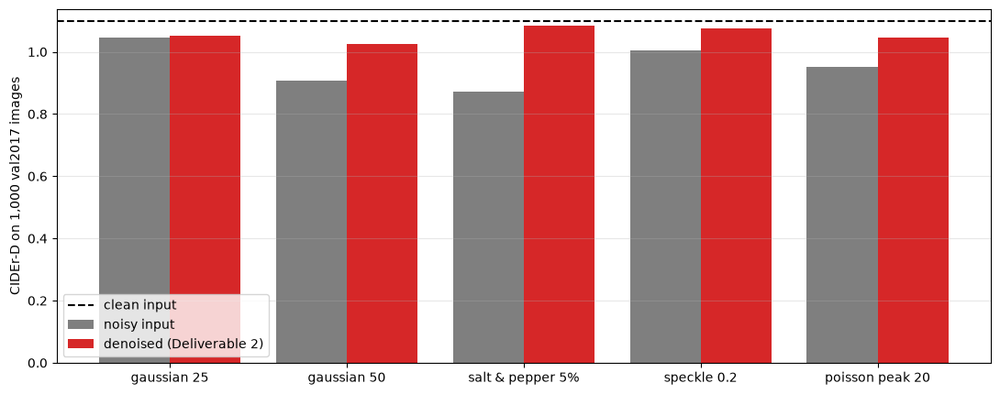

In [20]:
N_NOISE = 1000
noise_refs = val.caps[:N_NOISE]


def features_batch(imgs, batch=16):
    x = extractor("inception"); out = []
    for s in range(0, len(imgs), batch):
        b = tf.stack([tf.image.resize(tf.constant(i * 255.0), (x["size"], x["size"])) for i in imgs[s:s + batch]])
        out.append(x["net"](b).numpy().astype(np.float32))
    return np.concatenate(out)


def e1_captions(chunk=100):
    out = collections.defaultdict(list)
    for a in range(0, N_NOISE, chunk):
        imgs = [read_image(val.path(k)) for k in range(a, a + chunk)]
        out["clean"] += caption_features(features_batch(imgs))
        out["clean, denoised"] += caption_features(features_batch([denoise(i) for i in imgs]))
        for c, (cond, (kind, level)) in enumerate(CONDITIONS.items()):
            noisy = [add_noise(i, kind, level, seed=(SEED, c, a + j)) for j, i in enumerate(imgs)]
            out[f"{cond}, noisy"] += caption_features(features_batch(noisy))
            out[f"{cond}, denoised"] += caption_features(features_batch([denoise(i) for i in noisy]))
    return dict(out)


e1 = cached("e1_denoiser_captions", e1_captions)
per_image = {k: cider_d(noise_refs, [c.split() for c in v])[1] for k, v in e1.items()}
rows = [{"condition": k.split(", ")[0], "input": k.split(", ")[1] if ", " in k else "clean",
         "CIDEr-D": per_image[k].mean(), "BLEU-4": bleu(noise_refs, [c.split() for c in v])[3]} for k, v in e1.items()]
noise_table = pd.DataFrame(rows).set_index(["condition", "input"])
display(noise_table.round(4))

draws = np.random.default_rng(SEED).integers(N_NOISE, size=(2000, N_NOISE))
rows = []
for cond in CONDITIONS:
    gain = per_image[f"{cond}, denoised"] - per_image[f"{cond}, noisy"]; means = gain[draws].mean(axis=1)
    lost = per_image["clean"].mean() - per_image[f"{cond}, noisy"].mean()
    rows.append({"condition": cond, "CIDEr-D gain": gain.mean(), "95 % low": np.percentile(means, 2.5), "95 % high": np.percentile(means, 97.5),
                 "share of the loss recovered": gain.mean() / max(lost, 1e-9)})
gain = per_image["clean, denoised"] - per_image["clean"]; means = gain[draws].mean(axis=1)
rows.append({"condition": "clean", "CIDEr-D gain": gain.mean(), "95 % low": np.percentile(means, 2.5), "95 % high": np.percentile(means, 97.5),
             "share of the loss recovered": np.nan})
display(pd.DataFrame(rows).set_index("condition").round(4))

labels = list(CONDITIONS); x = np.arange(len(labels))
fig, ax = plt.subplots(figsize=(11, 4.4))
ax.bar(x - 0.2, [noise_table.loc[(c, "noisy"), "CIDEr-D"] for c in labels], 0.4, label="noisy input", color="tab:gray")
ax.bar(x + 0.2, [noise_table.loc[(c, "denoised"), "CIDEr-D"] for c in labels], 0.4, label="denoised (Deliverable 2)", color="tab:red")
ax.axhline(noise_table.loc[("clean", "clean"), "CIDEr-D"], color="black", ls="--", label="clean input")
ax.set_xticks(x); ax.set_xticklabels(labels); ax.set_ylabel(f"CIDEr-D on {N_NOISE:,d} val2017 images"); ax.legend(); ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

**Reading.**
* **Gains.** Under four of the five noises, denoising improves the captions with intervals that exclude zero:
  * +0.21 CIDEr-D under salt and pepper;
  * +0.12 under Gaussian $\sigma = 50$;
  * +0.09 under Poisson;
  * +0.07 under speckle.

  This recovers 61 to 93 % of the loss caused by the noise.
* **Mild noise.** Gaussian $\sigma = 25$ costs only 0.055 CIDEr-D, and the gain (+0.006, interval -0.028 to 0.043) is not significant: InceptionV3 tolerates this level of noise.
* **Clean images.** The denoiser changes nothing (+0.001, interval -0.001 to 0.003). It can therefore be applied to every image without first detecting whether it is noisy.
* **Salt and pepper.** This is the most harmful noise for the captioner (-0.23) and the best corrected (93 %). The impulses are far from natural image statistics, and the denoiser removes them almost completely.

## Extension E2 - Order of the chain and errors of the gate

*Why:* the Deliverable 1 classifier was trained on clean images, while a real archive contains noisy scans. A noisy photograph wrongly rejected never reaches the captioner, so the gate cannot be evaluated on clean images alone. This also decides whether the denoiser goes before the gate or after it.

**Method.** 1,000 images of the Deliverable 1 test split (500 photographs and 500 non-photographs, 125 of each other class), limited to 512 pixels on the longest side. For each noise condition, the gate decides on the noisy image and on the denoised image. We report the recall on photographs, the share of non-photographs wrongly accepted, and the balanced accuracy, with the 95 % Wilson interval of the recall.

In [21]:
gate_rng = np.random.default_rng(SEED)
gate_files = [(f_, 1) for f_ in gate_rng.choice(sorted(d1_files["Photo"]), 500, replace=False)]
for label in ("Painting", "Schematics", "Sketch", "Text"):
    gate_files += [(f_, 0) for f_ in gate_rng.choice(sorted(d1_files[label]), 125, replace=False)]
labels_gate = np.array([y_ for _, y_ in gate_files])


def gate_image(path):
    img = Image.open(path).convert("RGB")
    img.thumbnail((512, 512), Image.LANCZOS)
    return np.asarray(img, dtype=np.float32) / 255.0


def e2_probabilities():
    out = collections.defaultdict(list)
    for k, (path, _) in enumerate(gate_files):
        img = gate_image(path)
        out["clean|gate only"].append(photo_probability(img)); out["clean|denoise, then gate"].append(photo_probability(denoise(img)))
        for c, (cond, (kind, level)) in enumerate(CONDITIONS.items()):
            noisy = add_noise(img, kind, level, seed=(SEED, 100 + c, k))
            out[f"{cond}|gate only"].append(photo_probability(noisy)); out[f"{cond}|denoise, then gate"].append(photo_probability(denoise(noisy)))
    return dict(out)


def wilson(p, n, z=1.96):
    c = (p + z * z / (2 * n)) / (1 + z * z / n); h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return c - h, c + h


rows = []
for key, probs in cached("e2_gate", e2_probabilities).items():
    decided = np.array(probs) >= PHOTO_THRESHOLD; cond, order = key.split("|")
    recall, accepted = decided[labels_gate == 1].mean(), decided[labels_gate == 0].mean(); lo, hi = wilson(recall, 500)
    rows.append({"condition": cond, "order": order, "photo recall": recall, "recall 95 % interval": f"{lo:.3f}-{hi:.3f}",
                 "non-photos accepted": accepted, "balanced accuracy": (recall + 1 - accepted) / 2})
gate_table = pd.DataFrame(rows).set_index(["condition", "order"])
display(gate_table.round(3))

photo recall recall 95 % interval  non-photos accepted  balanced accuracy
condition        order                                                                                        
clean            gate only                  0.950          0.927-0.966                0.006              0.972
                 denoise, then gate         0.950          0.927-0.966                0.006              0.972
gaussian 25      gate only                  0.642          0.599-0.683                0.042              0.800
                 denoise, then gate         0.956          0.934-0.971                0.040              0.958
gaussian 50      gate only                  0.462          0.419-0.506                0.048              0.707
                 denoise, then gate         0.958          0.937-0.972                0.102              0.928
salt & pepper 5% gate only                  0.324          0.284-0.366                0.012              0.656
                 denoise, then gate         0.948          0.925-0.964                0.006              0.971
speckle 0.2      gate only                  0.740          0.700-0.777                0.024              0.858
                 denoise, then gate         0.970          0.951-0.982                0.048              0.961
poisson peak 20  gate only                  0.648          0.605-0.689                0.040              0.804
                 denoise, then gate         0.962          0.941-0.976                0.078              0.942

**Reading.**
* **Gate alone.** Applied directly to noisy images, the gate rejects many photographs. The recall falls from 0.950 on clean images to 0.462 under Gaussian $\sigma = 50$ and 0.324 under salt and pepper: up to two thirds of the photographs would never be captioned.
* **Denoiser first.** With the denoiser before the gate, the recall is 0.948-0.970 under every noise, within the interval of the clean recall.
* **Cost.** More non-photographs are accepted under strong Gaussian, Poisson and speckle noise (0.102, 0.078 and 0.048, against 0.048, 0.040 and 0.024 without the denoiser). The denoiser smooths some drawings and text images into images that the classifier takes for photographs.
* **Order of the chain.** The balanced accuracy is higher with the denoiser first in every noisy condition (0.928-0.971, against 0.656-0.858). An accepted non-photograph receives a wrong caption, while a rejected photograph is lost. This fixes the order used in Section 12: denoise, then gate, then caption.

## Extension E3 - Gender in the captions

*Why:* captions published in an archive should not assign a gender that the image does not show. COCO captions name men about twice as often as women, and captioning models are known to amplify such priors (Hendricks et al., 2018).

**Protocol** (Burns et al., 2018):
* An image is *male* (or *female*) when at least one of its references uses a male (or female) word and none uses the other.
* A caption is then *correct*, *wrong* (the other gender) or *neutral* (no gendered word).
* Human captions are scored the same way, with the first reference of each image against the other four.

**Neutral mode.** A rewriting to gender-neutral words (man/woman → person, boy/girl → child, he/she → they, ...) is the option offered for publication. Its cost is measured in CIDEr-D and CLIPScore.

In [22]:
MALE = {"man", "men", "boy", "boys", "male", "males", "gentleman", "gentlemen", "guy", "guys", "he", "his", "him", "himself",
        "father", "son", "husband", "brother", "businessman", "policeman", "fireman", "sportsman", "groom", "king", "dad"}
FEMALE = {"woman", "women", "girl", "girls", "female", "females", "lady", "ladies", "she", "her", "hers", "herself",
          "mother", "daughter", "wife", "sister", "businesswoman", "policewoman", "bride", "queen", "mom"}


def gender_of(words_):
    m, f_ = bool(MALE & set(words_)), bool(FEMALE & set(words_))
    return "male" if m and not f_ else "female" if f_ and not m else "both" if m and f_ else "none"


def reference_gender(refs):
    # 'male' ('female') if at least one reference uses a male (female) word and none uses the other
    g = {gender_of(r) for r in refs}
    m, f_ = any(x in ("male", "both") for x in g), any(x in ("female", "both") for x in g)
    return "male" if m and not f_ else "female" if f_ and not m else None


def gender_table(references, hypotheses):
    counts = collections.Counter()
    for refs, h in zip(references, hypotheses):
        truth = reference_gender(refs)
        if truth:
            p = gender_of(h)
            counts[truth, "correct" if p == truth else "neutral" if p == "none" else "wrong"] += 1
    rows = {}
    for t in ("male", "female"):
        n = sum(counts[t, k] for k in ("correct", "wrong", "neutral"))
        rows[t] = {"images": n, **{k: counts[t, k] / max(n, 1) for k in ("correct", "wrong", "neutral")}}
    return rows


def gender():
    out = {}
    for m in weights:
        caps_ = [c.split() for c in val_caps[m]]
        out[m] = gender_table(val.caps, caps_)
        out[f"{m}_neutral_cider"] = cider_d(val.caps, [neutralise(c) for c in caps_])[0]
        out[f"{m}_cider"] = cider_d(val.caps, caps_)[0]
    out["human_first_ref"] = gender_table([r[1:] for r in val.caps], [r[0] for r in val.caps])
    return out


gen = cached("gender", gender)
rows = []
for label, key in [("human (first reference)", "human_first_ref"), ("cross-entropy", "xe"), ("SCST (final)", "scst")]:
    for g in ("male", "female"):
        rows.append({"captions": label, "image gender": g, **gen[key][g]})
display(pd.DataFrame(rows).style.format({"correct": "{:.1%}", "wrong": "{:.1%}", "neutral": "{:.1%}"}).hide(axis="index"))
print(f"neutral mode, final model: val CIDEr-D {gen['scst_cider']:.3f} -> {gen['scst_neutral_cider']:.3f} | "
      f"CLIP-S {clip['scst_val']['CLIP-S']:.3f} -> {clip['scst_val_neutral']['CLIP-S']:.3f}")

captions,image gender,images,correct,wrong,neutral
human (first reference),male,1197,60.2%,1.4%,38.3%
human (first reference),female,502,70.7%,1.6%,27.7%
cross-entropy,male,1224,55.3%,6.5%,38.2%
cross-entropy,female,507,42.6%,20.7%,36.7%
SCST (final),male,1224,57.7%,9.5%,32.8%
SCST (final),female,507,43.4%,25.0%,31.6%


neutral mode, final model: val CIDEr-D 1.056 -> 1.020 | CLIP-S 0.719 -> 0.721


**Reading.**
* **Human captions** give the wrong gender for 1.4-1.6 % of the images.
* **The model** is wrong far more often, and asymmetrically: 9.5 % of the male images and 25.0 % of the female images. One woman in four is described as a man, which reproduces the imbalance of the training captions.
* **Effect of SCST.** SCST increases the errors (6.5 to 9.5 % for male images, 20.7 to 25.0 % for female images) and reduces the neutral captions. The CIDEr-D reward favours the gendered words that dominate the references, and a wrong guess costs little in that reward.
* **Neutral mode.** It removes the gender errors by construction. It costs 0.036 CIDEr-D (1.056 to 1.020), measured against references that are themselves gendered, while CLIPScore does not decrease (0.719 to 0.721). The neutral mode is recommended for publication: the CIDEr-D loss reflects the references, not a loss of content.

## Extension E4 - A second captioner: ConvNeXt-XL features and a Transformer decoder

*Why:* the brief fixes InceptionV3 and an RNN decoder. TouNum should know how much a stronger CNN and a different decoder would add, and which of the two matters. This extension trains a second captioner on the same data, vocabulary, training stages and evaluation, and separates the two factors with a third run (ConvNeXt-XL features with the GRU decoder).

**CNN.** ConvNeXt-XL (Liu et al., 2022), ImageNet-22k pre-training fine-tuned on ImageNet-1k at 384 x 384, head removed, frozen. Its last stage gives a 12 x 12 x 2,048 map (144 regions), stored as float16 like the InceptionV3 features (Section 4).

**Transformer decoder.** An encoder-decoder Transformer (Vaswani et al., 2017) with pre-LayerNorm layers, $d = 512$, 8 heads and feed-forward width 2,048:
* **Encoder** (`TEncoder`, 3 layers). The regions are normalised and projected, $x_i = \mathrm{ReLU}(W\,\mathrm{LN}(f_i)) + p_i$, with a learned position $p_i$ per grid cell. Each layer applies $x \leftarrow x + \mathrm{MHA}(\mathrm{LN}(x))$, then $x \leftarrow x + \mathrm{FFN}(\mathrm{LN}(x))$, with GELU activations. Self-attention lets each region carry context, such as an object together with its surface.
* **Decoder** (`TDecoder`, 3 layers). Word embeddings are scaled by $\sqrt d$ and given learned positions. Each layer applies causal self-attention over the words written so far, cross-attention from the words to the encoded regions, then the FFN. The logits are $\mathrm{LN}(h_t)\,E^\top$, tied with the embedding.
* **Teacher forcing** computes all positions in one pass under the causal mask (`forward`). **Decoding** (`step`) is incremental: the keys and values of the regions are computed once per image, and those of the words already written are cached in the decoder state, so `step` has the same interface as the GRU and the same beam search serves both.

**Training.** As for the GRU, with the settings of `TFM_CFG`: AdamW (learning rate $6 \cdot 10^{-4}$, $\beta_2 = 0.98$), image-wise batches (Section 5), dropout 0.1, gradients clipped to norm 1, 12 epochs, then SCST.

In [23]:
class Attn(layers.Layer):
    """Multi-head scaled dot-product attention; kv() and attend() are separate so that keys and values can be cached."""
    def __init__(self, d, heads, dropout):
        super().__init__(); self.h, self.dh = heads, d // heads
        self.q, self.k, self.v, self.o = (layers.Dense(d) for _ in range(4)); self.drop = layers.Dropout(dropout)

    def split(self, x):                                       # (B, L, d) -> (B, h, L, dh)
        return tf.transpose(tf.reshape(x, (tf.shape(x)[0], -1, self.h, self.dh)), (0, 2, 1, 3))

    def kv(self, m):
        return self.split(self.k(m)), self.split(self.v(m))

    def attend(self, x, k, v, mask=None, training=False):
        """x (B, Lq, d) attends to k, v (B, h, Lk, dh); mask broadcastable to (B, h, Lq, Lk), True = visible."""
        s = tf.matmul(self.split(self.q(x)), k, transpose_b=True) / math.sqrt(self.dh)
        if mask is not None:
            s = tf.where(mask, s, -1e9)
        a = tf.nn.softmax(s, -1); o = tf.matmul(self.drop(a, training=training), v)
        o = tf.reshape(tf.transpose(o, (0, 2, 1, 3)), (tf.shape(x)[0], -1, self.h * self.dh))
        return self.o(o), a

    def call(self, x, m, vis=None, training=False):
        k, v = self.kv(m); return self.attend(x, k, v, vis, training)


def ffn(d, ff, dropout):
    return keras.Sequential([layers.Dense(ff, activation="gelu"), layers.Dropout(dropout), layers.Dense(d)])


class EncLayer(layers.Layer):
    def __init__(self, d, heads, ff, dropout):
        super().__init__()
        self.n1, self.n2 = layers.LayerNormalization(), layers.LayerNormalization()
        self.att = Attn(d, heads, dropout); self.ff = ffn(d, ff, dropout); self.drop = layers.Dropout(dropout)

    def call(self, x, training=False):
        h = self.n1(x); x = x + self.drop(self.att(h, h, training=training)[0], training=training)
        return x + self.drop(self.ff(self.n2(x), training=training), training=training)


class DecLayer(layers.Layer):
    def __init__(self, d, heads, ff, dropout):
        super().__init__()
        self.n1, self.n2, self.n3 = (layers.LayerNormalization() for _ in range(3))
        self.self_att, self.cross = Attn(d, heads, dropout), Attn(d, heads, dropout)
        self.ff = ffn(d, ff, dropout); self.drop = layers.Dropout(dropout)

    def call(self, x, cross_kv, self_kv=None, vis=None, training=False):
        """Teacher forcing: self_kv None, causal mask. Decoding: x is the new word, self_kv the cache including it."""
        h = self.n1(x); k, v = self.self_att.kv(h) if self_kv is None else self_kv
        x = x + self.drop(self.self_att.attend(h, k, v, vis, training)[0], training=training)
        c, a = self.cross.attend(self.n2(x), *cross_kv, training=training)
        x = x + self.drop(c, training=training)
        return x + self.drop(self.ff(self.n3(x), training=training), training=training), a


class TEncoder(keras.Model):
    """Region features -> LayerNorm, Dense, ReLU, learned position of each grid cell, then self-attention layers."""
    def __init__(self, d, n_layers, heads, ff, dropout, regions):
        super().__init__()
        self.norm = layers.LayerNormalization(); self.fc = layers.Dense(d); self.drop = layers.Dropout(dropout)
        self.pos = self.add_weight(shape=(regions, d), initializer=keras.initializers.RandomNormal(stddev=0.02), name="pos")
        self.blocks = [EncLayer(d, heads, ff, dropout) for _ in range(n_layers)]; self.out_norm = layers.LayerNormalization()

    def call(self, x, training=False):
        x = self.drop(tf.nn.relu(self.fc(self.norm(x))), training=training) + self.pos
        for b in self.blocks:
            x = b(x, training=training)
        return self.out_norm(x)


class TDecoder(keras.Model):
    """Causal decoder over word embeddings (tied with the output layer) with cross-attention to the encoded regions."""
    def __init__(self, d, n_layers, heads, ff, vocab, dropout, length):
        super().__init__(); self.d, self.length, self.heads = d, length, heads
        self.embedding = layers.Embedding(vocab, d)
        self.pos = self.add_weight(shape=(length, d), initializer=keras.initializers.RandomNormal(stddev=0.02), name="pos")
        self.blocks = [DecLayer(d, heads, ff, dropout) for _ in range(n_layers)]
        self.out_norm = layers.LayerNormalization(); self.drop = layers.Dropout(dropout)

    def embed(self, words_, pos, training=False):
        return self.drop(self.embedding(words_) * math.sqrt(self.d) + pos, training=training)

    def forward(self, words_, memory, training=False):
        """words (B, L) -> outputs (B, L, d) and the cross-attention of the last layer, averaged over heads (B, L, R)."""
        L = words_.shape[1]; x = self.embed(words_, self.pos[:L], training)
        causal = tf.linalg.band_part(tf.ones((L, L), tf.bool), -1, 0)
        for b in self.blocks:
            x, a = b(x, b.cross.kv(memory), vis=causal, training=training)
        return self.out_norm(x), tf.reduce_mean(a, axis=1)

    def prepare(self, features):
        # keys and values of the regions for every layer, computed once per image
        return tuple(t for b in self.blocks for t in b.cross.kv(features)), features

    def initial_state(self, n):
        z = tf.zeros((n, self.heads, self.length, self.d // self.heads))
        return (tf.zeros((n,), tf.int32),) + (z,) * (2 * len(self.blocks))

    def step(self, word, features, prepared, state, training=False):
        pos, cache = state[0], state[1:]; cross = prepared[0]
        x = self.embed(word[:, None], tf.gather(self.pos, pos)[:, None], training)
        put = tf.one_hot(pos, self.length)[:, None, :, None]                  # (n, 1, L, 1): where the new word goes
        visible = tf.sequence_mask(pos + 1, self.length)[:, None, None, :]    # (n, 1, 1, L)
        new = []
        for i, b in enumerate(self.blocks):
            h = b.n1(x); k1, v1 = b.self_att.kv(h)
            k = cache[2 * i] * (1 - put) + k1 * put; v = cache[2 * i + 1] * (1 - put) + v1 * put; new += [k, v]
            x, a = b(x, (cross[2 * i], cross[2 * i + 1]), self_kv=(k, v), vis=visible, training=training)
        return self.out_norm(x)[:, 0], (pos + 1,) + tuple(new), tf.reduce_mean(a, axis=1)[:, 0, :, None]

    def logits(self, out, training=False):
        return tf.matmul(out, self.embedding.embeddings, transpose_b=True)


def build_transformer(cfg, V, R):
    enc = TEncoder(cfg["d"], cfg["enc_layers"], cfg["heads"], cfg["ff"], cfg["dropout"], R)
    dec = TDecoder(cfg["d"], cfg["dec_layers"], cfg["heads"], cfg["ff"], V, cfg["dropout"], T - 1)
    f0 = enc(tf.zeros((1, R, D))); o0, *_ = dec.step(tf.zeros((1,), tf.int32), f0, dec.prepare(f0), dec.initial_state(1))
    dec.logits(o0)                                # all weights exist before any are loaded
    dec.built = True                              # the decoder is used through step/forward, never through call()
    return enc, dec


gru_val_caps, gru_metrics, gru_clip = val_caps, metrics, clip          # main captioner (Sections 10 and 11)
use("transformer")
print(f"Transformer: encoder {n_params(enc):,d} + decoder {n_params(dec):,d} = {n_params(enc, dec):,d} trainable weights")
with tf.device("/CPU:0"):                    # incremental decoding reproduces the one-pass outputs (exact float32 arithmetic)
    f, y = next(image_caption_batches(train, im, seq, len(train.names), 4, np.random.default_rng(0), 1))
    w_ = tf.constant(y[:4, :-1]); fe = enc(tf.constant(f[:4])); ref, _ = dec.forward(w_, fe); prep = dec.prepare(fe)
    st = dec.initial_state(4); outs = []
    for t in range(T - 1):
        o, st, _ = dec.step(w_[:, t], fe, prep, st); outs.append(o)
print("max |step - forward| over 21 positions:", float(tf.reduce_max(tf.abs(tf.stack(outs, 1) - ref))))

Transformer: encoder 10,585,088 + decoder 17,895,936 = 28,481,024 trainable weights


max |step - forward| over 21 positions: 1.6689300537109375e-06


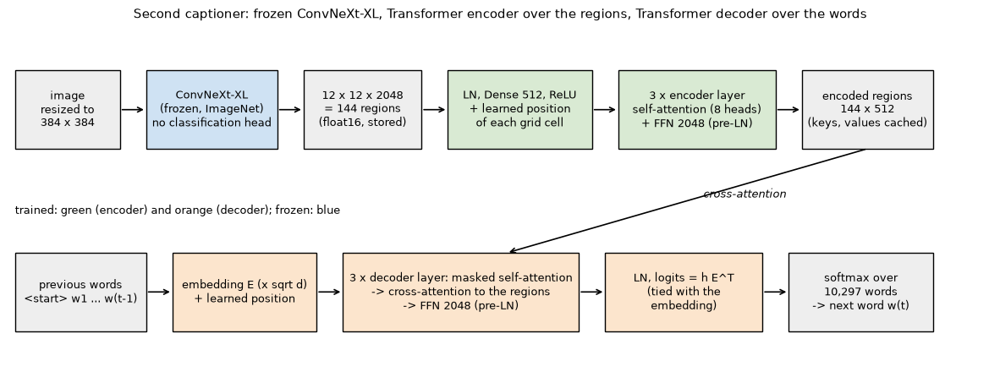

In [24]:
# schematic of the second captioner
fig, ax = plt.subplots(figsize=(15, 5.2)); ax.set_xlim(0, 15); ax.set_ylim(0, 5.2); ax.axis("off")
def box(x, y, w, h, text, color):
    ax.add_patch(plt.Rectangle((x, y), w, h, facecolor=color, edgecolor="black", lw=1))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=9)
def arrow(x0, y0, x1, y1):
    ax.annotate("", (x1, y1), (x0, y0), arrowprops=dict(arrowstyle="->", lw=1.2))
box(0.1, 3.3, 1.6, 1.2, "image\nresized to\n384 x 384", "#eeeeee")
box(2.1, 3.3, 2.0, 1.2, "ConvNeXt-XL\n(frozen, ImageNet)\nno classification head", "#cfe2f3")
box(4.5, 3.3, 1.8, 1.2, "12 x 12 x 2048\n= 144 regions\n(float16, stored)", "#eeeeee")
box(6.7, 3.3, 2.2, 1.2, "LN, Dense 512, ReLU\n+ learned position\nof each grid cell", "#d9ead3")
box(9.3, 3.3, 2.4, 1.2, "3 x encoder layer\nself-attention (8 heads)\n+ FFN 2048 (pre-LN)", "#d9ead3")
box(12.1, 3.3, 2.0, 1.2, "encoded regions\n144 x 512\n(keys, values cached)", "#eeeeee")
box(0.1, 0.5, 2.0, 1.2, "previous words\n<start> w1 ... w(t-1)", "#eeeeee")
box(2.5, 0.5, 2.2, 1.2, "embedding E (x sqrt d)\n+ learned position", "#fce5cd")
box(5.1, 0.5, 3.6, 1.2, "3 x decoder layer: masked self-attention\n-> cross-attention to the regions\n-> FFN 2048 (pre-LN)", "#fce5cd")
box(9.1, 0.5, 2.4, 1.2, "LN, logits = h E^T\n(tied with the\nembedding)", "#fce5cd")
box(11.9, 0.5, 2.2, 1.2, f"softmax over\n{V:,d} words\n-> next word w(t)", "#eeeeee")
for x0, x1 in [(1.7, 2.1), (4.1, 4.5), (6.3, 6.7), (8.9, 9.3), (11.7, 12.1)]:
    arrow(x0, 3.9, x1, 3.9)
for x0, x1 in [(2.1, 2.5), (4.7, 5.1), (8.7, 9.1), (11.5, 11.9)]:
    arrow(x0, 1.1, x1, 1.1)
arrow(13.1, 3.3, 7.6, 1.7)
ax.text(10.6, 2.55, "cross-attention", fontsize=9, style="italic")
ax.text(0.1, 2.3, "trained: green (encoder) and orange (decoder); frozen: blue", fontsize=9)
ax.set_title("Second captioner: frozen ConvNeXt-XL, Transformer encoder over the regions, Transformer decoder over the words", fontsize=11)
plt.show()

**Pilots.** The CNN, the decoder and their settings were chosen on 20,000 training images and 2,500 validation images, with greedy CIDEr-D:
* **CNN**, with the GRU decoder: InceptionV3, EfficientNetV2-L and ConvNeXt-XL, and ConvNeXt-XL with its last block fine-tuned.
* **Decoder**, on ConvNeXt-XL features: the GRU, regularised (label smoothing 0.1, weight decay 0.01, dropout 0.2 on the regions), against four Transformer variants trained for 6 epochs (base setting, dropout 0.3, learning rate $6 \cdot 10^{-4}$, no encoder layers). The two best variants were repeated with a second seed.
* **SCST learning rate**, 2 epochs from the best Transformer: $10^{-5}$ and $5 \cdot 10^{-5}$.

**Full data.** Three captioners were trained on all of `train2017` with the cross-entropy stage, which separates the two factors: InceptionV3 + GRU (the main model), ConvNeXt-XL + GRU, and ConvNeXt-XL + Transformer.

"CNN (GRU decoder, pilot)",input,grid,val CIDEr-D
InceptionV3,299,8 x 8 x 2048,0.806
EfficientNetV2-L,480,15 x 15 x 1280,0.946
ConvNeXt-XL,384,12 x 12 x 2048,1.051
"ConvNeXt-XL, last block fine-tuned",384,12 x 12 x 2048,1.037


Transformer variant,seed 42,seed 43
base,1.080,1.079
learning rate 6e-4,1.104,1.071


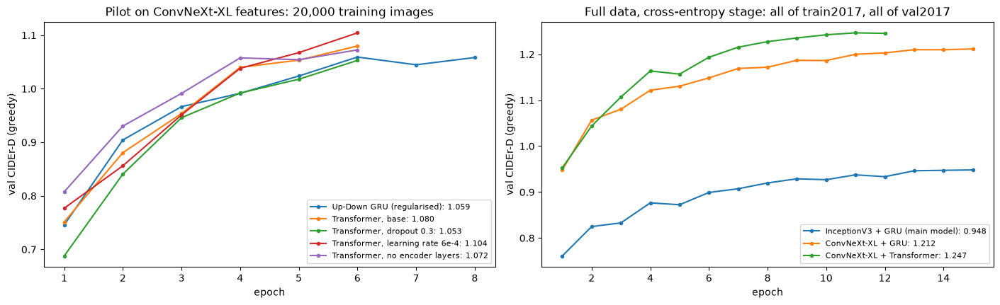

In [25]:
def history(run):
    return json.loads((RUNS / run / "hist.json").read_text())


def best_cider(run, phase="xe"):
    return max(h["cider"] for h in history(run) if h["phase"] == phase)


pilots = pd.DataFrame([("InceptionV3", "299", "8 x 8 x 2048", best_cider("p_inception")),
                       ("EfficientNetV2-L", "480", "15 x 15 x 1280", best_cider("p_effv2l")),
                       ("ConvNeXt-XL", "384", "12 x 12 x 2048", best_cider("p_convnext_xl")),
                       ("ConvNeXt-XL, last block fine-tuned", "384", "12 x 12 x 2048", best_cider("p_ft"))],
                      columns=["CNN (GRU decoder, pilot)", "input", "grid", "val CIDEr-D"])
display(pilots.style.format({"val CIDEr-D": "{:.3f}"}).hide(axis="index"))
seeds = pd.DataFrame([{"Transformer variant": "base", "seed 42": best_cider("t_c1"), "seed 43": best_cider("t_c1_s43")},
                      {"Transformer variant": "learning rate 6e-4", "seed 42": best_cider("t_c3"), "seed 43": best_cider("t_c3_s43")}])
display(seeds.style.format({"seed 42": "{:.3f}", "seed 43": "{:.3f}"}).hide(axis="index"))

screen = {"Up-Down GRU (regularised)": "p_reg", "Transformer, base": "t_c1", "Transformer, dropout 0.3": "t_c2",
          "Transformer, learning rate 6e-4": "t_c3", "Transformer, no encoder layers": "t_c6"}
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2), constrained_layout=True)
for label, run in screen.items():
    h = [x for x in history(run) if x["phase"] == "xe"]
    ax[0].plot([x["epoch"] for x in h], [x["cider"] for x in h], marker="o", ms=3, label=f"{label}: {best_cider(run):.3f}")
ax[0].set(xlabel="epoch", ylabel="val CIDEr-D (greedy)", title="Pilot on ConvNeXt-XL features: 20,000 training images"); ax[0].legend(fontsize=8)
full = {"InceptionV3 + GRU (main model)": "gru_inception", "ConvNeXt-XL + GRU": "full", "ConvNeXt-XL + Transformer": "final"}
for label, run in full.items():
    h = [x for x in history(run) if x["phase"] == "xe"]
    ax[1].plot([x["epoch"] for x in h], [x["cider"] for x in h], marker="o", ms=3, label=f"{label}: {best_cider(run):.3f}")
ax[1].set(xlabel="epoch", ylabel="val CIDEr-D (greedy)", title="Full data, cross-entropy stage: all of train2017, all of val2017"); ax[1].legend(fontsize=8)
plt.show()

**Reading.**
* **Pilot** (20,000 training images, same GRU decoder). The CNN alone changes the validation CIDEr-D from 0.806 (InceptionV3) to 0.946 (EfficientNetV2-L) and 1.051 (ConvNeXt-XL). Fine-tuning the last ConvNeXt block does not help (1.037), so the features stay frozen.
* **Full data, cross-entropy stage.**

  | captioner | CIDEr-D |
  |---|---|
  | InceptionV3 + GRU | 0.948 |
  | ConvNeXt-XL + GRU | 1.212 |
  | ConvNeXt-XL + Transformer | 1.247 |

  Of the 0.299 gap, the CNN accounts for 0.264 and the decoder for 0.035.
* **Seeds.** Two seeds of the same pilot Transformer configuration differ by up to 0.033. This is as large as the contribution of the decoder, and eight times smaller than that of the CNN.

,XE val CIDEr-D (greedy),BLEU-4,METEOR,ROUGE-L,CIDEr-D,SPICE,CLIP-S val,CLIP-S test2017,truncated endings
InceptionV3 + GRU (main),0.948,0.325,0.255,0.542,1.056,0.192,0.719,0.722,0.000
ConvNeXt-XL + Transformer,1.247,0.414,0.302,0.602,1.395,0.241,0.766,0.769,0.001
"ConvNeXt-XL + Transformer, SCST reward on the words only",1.247,0.408,0.300,0.598,1.413,0.235,-,-,0.393


human captions: CLIP-S val 0.777 | trainable weights: Transformer 28,481,024


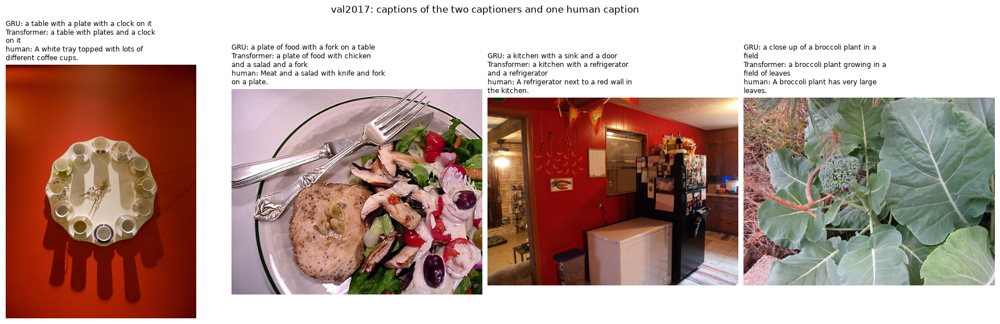

In [26]:
grid_t = cached("decoding", decoding_grid); W, P = max(grid_t, key=lambda r: r["cider"])["width"], max(grid_t, key=lambda r: r["cider"])["power"]
val_caps = {m: cached(f"val_captions_{m}", lambda m=m: captions_of(m, val)) for m in weights}
metrics = {m: cached(f"coco_metrics_{m}", lambda m=m: coco_metrics(m)) for m in weights}
clip = cached("clip", clip_scores)
words_only = json.loads((RUNS / "scst_words_only" / "coco_metrics_scst.json").read_text())
words_only_caps = json.loads((RUNS / "scst_words_only" / "val_captions_scst.json").read_text())

rows = {}
for label, met, cl, caps_, run in [("InceptionV3 + GRU (main)", gru_metrics, gru_clip, gru_val_caps, "gru_inception"),
                                   ("ConvNeXt-XL + Transformer", metrics, clip, val_caps, "final")]:
    rows[label] = {"XE val CIDEr-D (greedy)": best_cider(run), **{k: met["scst"][k] for k in ("BLEU-4", "METEOR", "ROUGE-L", "CIDEr-D", "SPICE")},
                   "CLIP-S val": cl["scst_val"]["CLIP-S"], "CLIP-S test2017": cl["final_test"]["CLIP-S"],
                   "truncated endings": dangling(caps_["scst"])}
rows["ConvNeXt-XL + Transformer, SCST reward on the words only"] = {"XE val CIDEr-D (greedy)": best_cider("final"),
    **{k: words_only[k] for k in ("BLEU-4", "METEOR", "ROUGE-L", "CIDEr-D", "SPICE")}, "truncated endings": dangling(words_only_caps)}
display(pd.DataFrame(rows).T.style.format("{:.3f}", na_rep="-"))
print(f"human captions: CLIP-S val {clip['human_val']['CLIP-S']:.3f} | trainable weights: Transformer {n_params(enc, dec):,d}")

fig, axes = plt.subplots(1, 4, figsize=(18, 5.6), constrained_layout=True)
for ax, i in zip(axes, range(8, 12)):
    ax.imshow(Image.open(val.path(i)).convert("RGB")); ax.axis("off")
    ax.set_title(textwrap.fill("GRU: " + gru_val_caps["scst"][i], 44) + "\n" + textwrap.fill("Transformer: " + val_caps["scst"][i], 44) + "\n"
                 + textwrap.fill("human: " + val.raw[i][0], 44), fontsize=8.5, loc="left")
plt.suptitle("val2017: captions of the two captioners and one human caption", fontsize=12)
plt.show()

**Reading.**
* **Scores.** After SCST and beam search, the second captioner reaches 1.395 CIDEr-D against 1.056, and improves all of the metrics (BLEU-4 0.414, SPICE 0.241). On `test2017` its CLIPScore is 0.769, against 0.722 for the main model and 0.777 for human captions.
* **Examples.** The difference is in specific nouns and in the number of objects named ("plates and a clock", "chicken and a salad", "a sink and a refrigerator").
* **End-of-sentence term.** The third row justifies the end-of-sentence term of the SCST reward. With a reward on the words only, CIDEr-D rises slightly (1.413), but 39 % of the captions end on a truncated phrase, which CIDEr-D barely penalises.
* **Consequence for the delivered model.** The delivered captioner remains the InceptionV3 + GRU model of the brief. Replacing the CNN is the largest available improvement; a Transformer decoder adds a smaller gain.

## Section 13 - Limits

* **Domain.** COCO contains recent colour photographs of everyday scenes. Archive photographs (old prints, black and white, posed groups, period objects) are outside this distribution. They are captioned in generic terms, and the vocabulary of 10,297 words has no period-specific terms.
* **Synthetic noise.** E1 and E2 use the synthetic noises of Deliverable 2. Real scan defects (blur, fading, JPEG artefacts, scratches, folds) have not been tested.
* **Resolution of the features.** The 8 x 8 grid of InceptionV3 limits small objects, counting and spatial relations. E4 shows that the CNN, more than the decoder, bounds the quality of the captions.
* **Gender.** The final model gives the wrong gender for a quarter of the female images (E3). Without the neutral mode, its captions should not be published as they are.
* **Gate.** The threshold $P(\text{photo}) \geq 0.5$ was set on clean images. Once the denoiser is applied first, it accepts up to 10 % of the non-photographs under strong noise (E2).
* **Evaluation.**
  * `test2017` has no public captions, so it is scored with CLIPScore only.
  * The automatic metrics compare wording with five references and do not check facts.
  * The main model was trained with a single seed. On the pilot configurations, the variation between seeds is about 0.03 CIDEr-D.

## Section 14 - Conclusion

* **Captioner.** The delivered captioner follows the brief: an InceptionV3 encoder and an RNN decoder, made of two GRU layers of 768 cells with additive attention over 64 regions, with 18.3 M trainable weights.
  * Trained with cross-entropy, then SCST, it reaches 1.056 CIDEr-D, 0.325 BLEU-4 and 0.192 SPICE on `val2017`.
  * On `test2017` its CLIPScore is 0.722, against 0.777 for human captions.
  * The model is saved and reloads with identical captions.
* **Complete chain.** The chain goes from an unidentified image to a captioned photograph: the denoiser of Deliverable 2, the photo classifier of Deliverable 1, then the captioner, with the captions written to a CSV file. Its order is supported by measurement:
  * Under noise, the gate alone loses up to two thirds of the photographs, while the denoiser placed first restores a recall of 0.95-0.97 (E2).
  * The denoiser recovers 61 to 93 % of the CIDEr-D lost under four of the five noises and leaves clean images unchanged (E1).
* **Recommendations for TouNum.**
  * Use the neutral mode before publication, given the gender errors (E3).
  * For a further gain, replace the CNN: ConvNeXt-XL features with a Transformer decoder reach 1.395 CIDEr-D and a CLIPScore close to that of human captions (E4).
  * Adapt the model to archive photographs and real scan defects; this remains the main open task.